# Module 2

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_1.h5 ...
Loaded 758,002 events over 56.95 seconds.
Total DAQ Trigger Rate: 13308.8 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 295.0 (±25.0)    | 304.0 (±25.0)    | 0.02    % | 0.01    % | 52,995      | 930.5      | SINGING! ⚠️ 
1     |  2, 3    | 213.0 (±25.0)    | 215.0 (±25.0)    | 0.02    % | 0.02    % | 29,824      | 523.6      | SINGING! ⚠️ 
2     |  4, 5    | 174.0 (±25.0)    | 204.0 (±25.0)    | 0.04    % | 0.05    % | 14,977      | 263.0      | SINGING! ⚠️ 
3     |  6, 7    | 204.0 (±25.0)    | 202.0 (±25.0)    | 0.01    % | 15.75   % | 183,473     | 3221.4     | SINGING! ⚠️ 
4     |  8, 9    | 219.0 (±25.0)    | 195.0 (±23.7)    | 1.16    % | 0.33    % | 1,206       | 21.2       | OK (Cosmic) 
5     | 10, 11   | 197.0 (±22.2)    | 204.0 (±19.3)    | 1.04    % | 0.21    % | 960         | 16.9       |

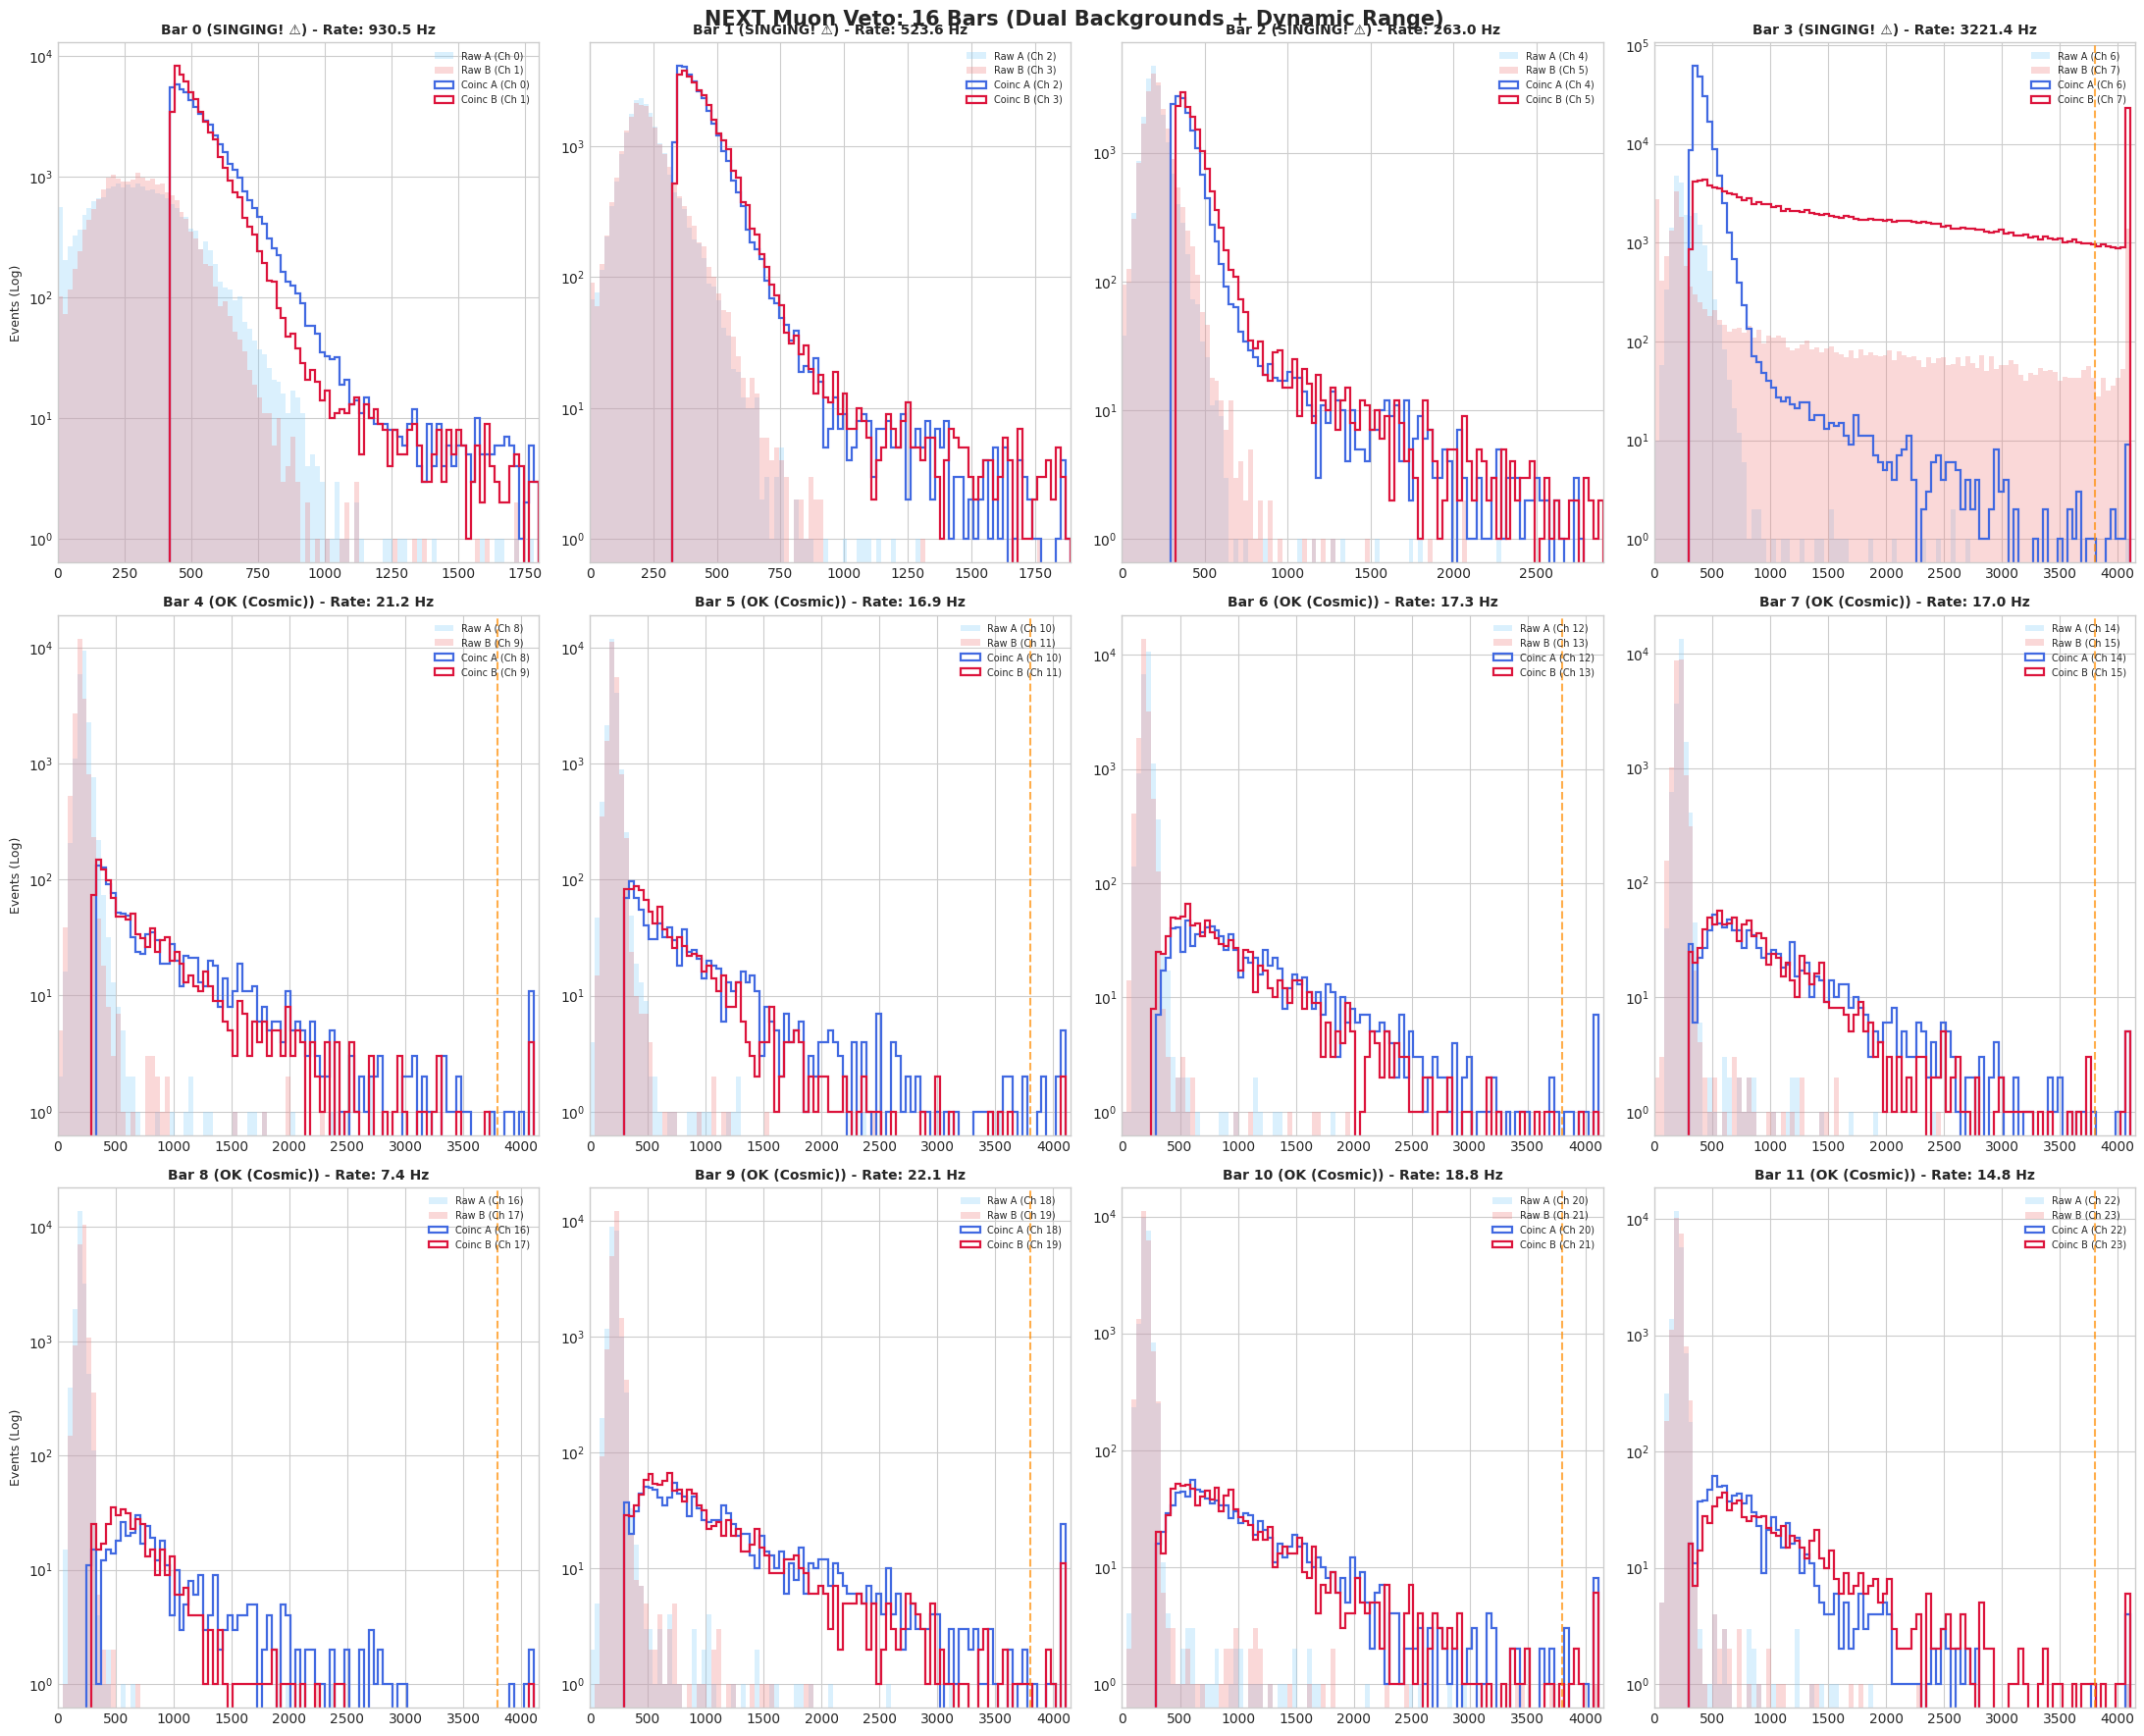

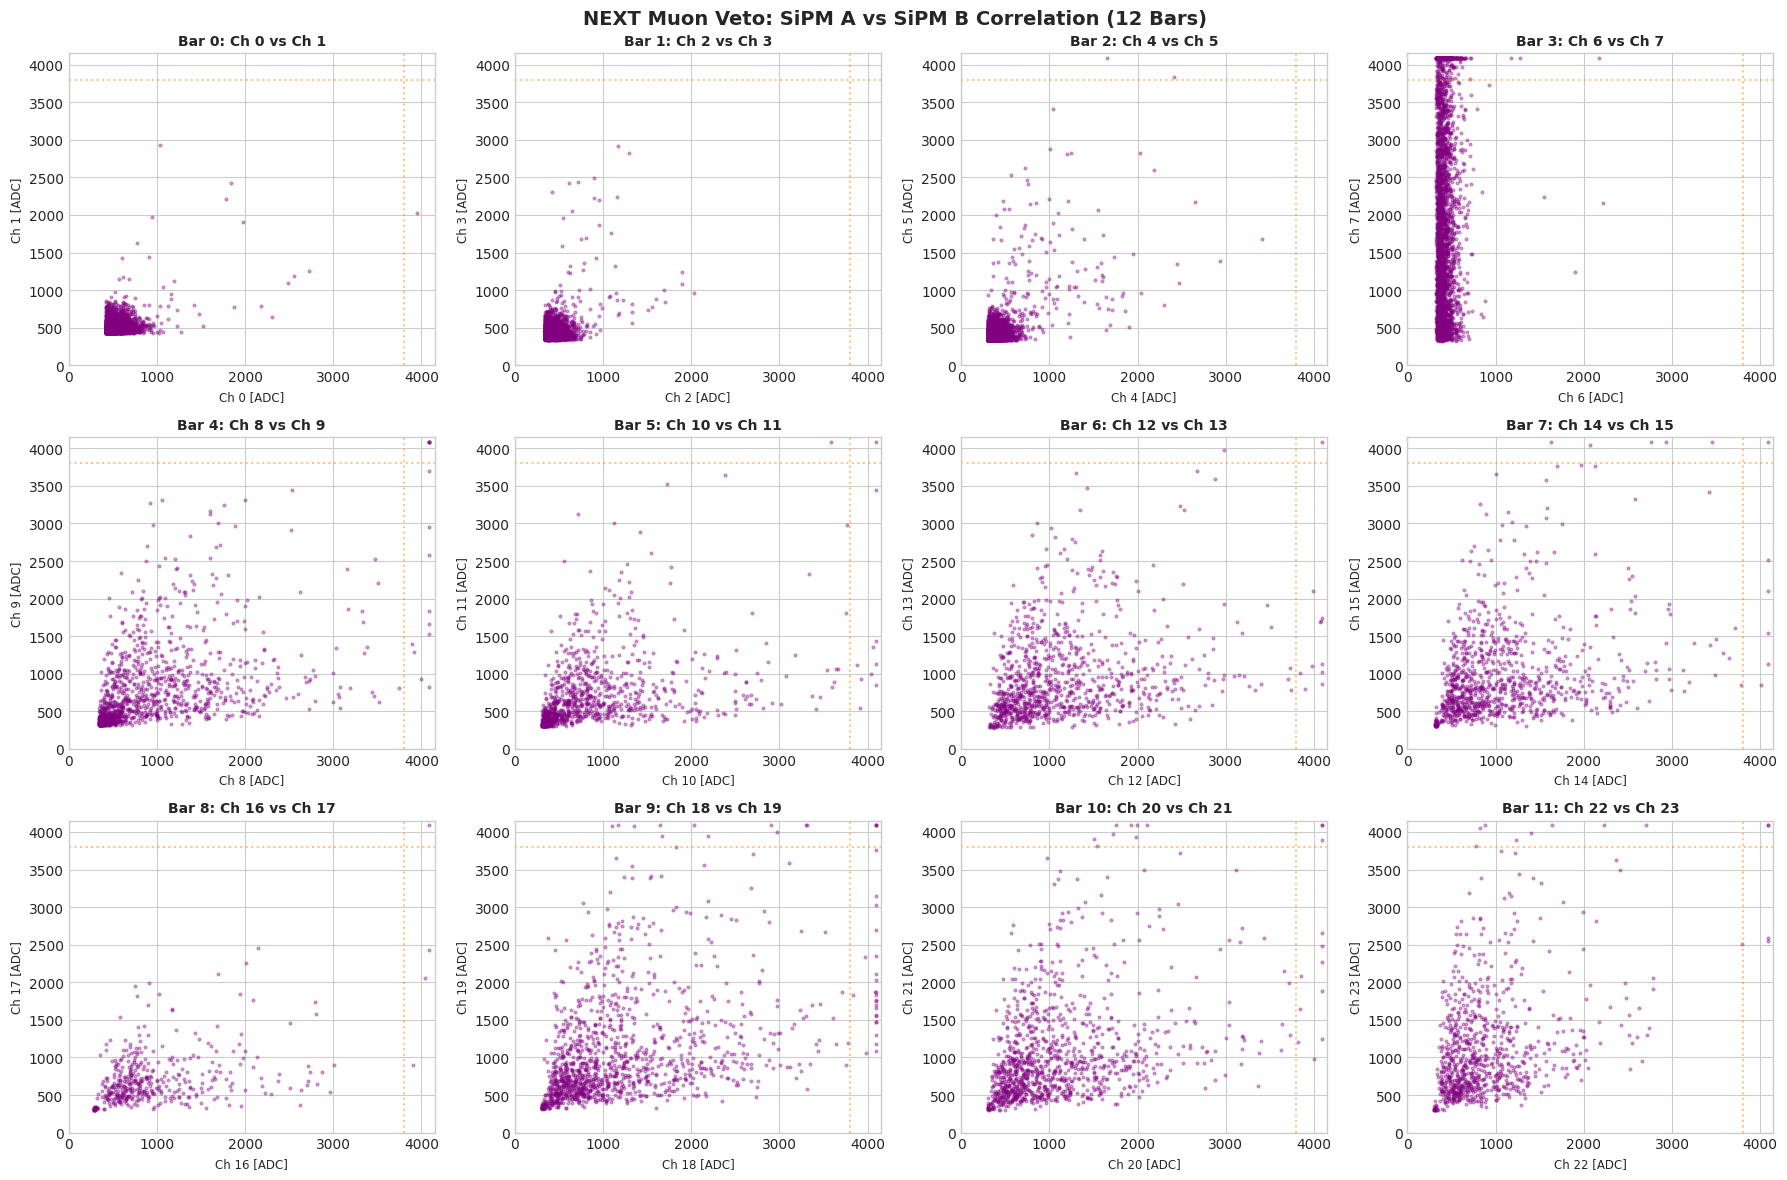

In [4]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_1.h5"

# All 16 bars mapped to the 32 CAEN channels
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION (All 32 Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")


# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        sub_indices = np.where(coinc_mask)[0]
        if len(sub_indices) > 3000:
            sub_indices = np.random.choice(sub_indices, 3000, replace=False)
        ax.scatter(q_a[sub_indices], q_b[sub_indices], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

# Hide any extra empty subplots
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: SiPM A vs SiPM B Correlation ({n_bars} Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_dynamic.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_dynamic.png")
print("\nDone! Now you can analyze any number of bars automatically.")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_2.h5 ...
Loaded 217,494 events over 37.00 seconds.
Total DAQ Trigger Rate: 5877.9 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 265.0 (±25.0)    | 272.0 (±25.0)    | 0.01    % | 0.02    % | 13,497      | 364.8      | SINGING! ⚠️ 
1     |  2, 3    | 223.0 (±25.0)    | 227.0 (±25.0)    | 0.00    % | 0.02    % | 12,360      | 334.0      | SINGING! ⚠️ 
2     |  4, 5    | 171.0 (±25.0)    | 209.0 (±25.0)    | 0.02    % | 0.03    % | 11,191      | 302.4      | SINGING! ⚠️ 
3     |  6, 7    | 205.0 (±25.0)    | 181.0 (±25.0)    | 0.02    % | 4.32    % | 39,809      | 1075.9     | SINGING! ⚠️ 
4     |  8, 9    | 211.0 (±25.0)    | 191.0 (±25.0)    | 0.33    % | 0.27    % | 1,506       | 40.7       | OK (Cosmic) 
5     | 10, 11   | 188.0 (±25.0)    | 196.0 (±20.8)    | 0.34    % | 0.09    % | 1,170       | 31.6       | 

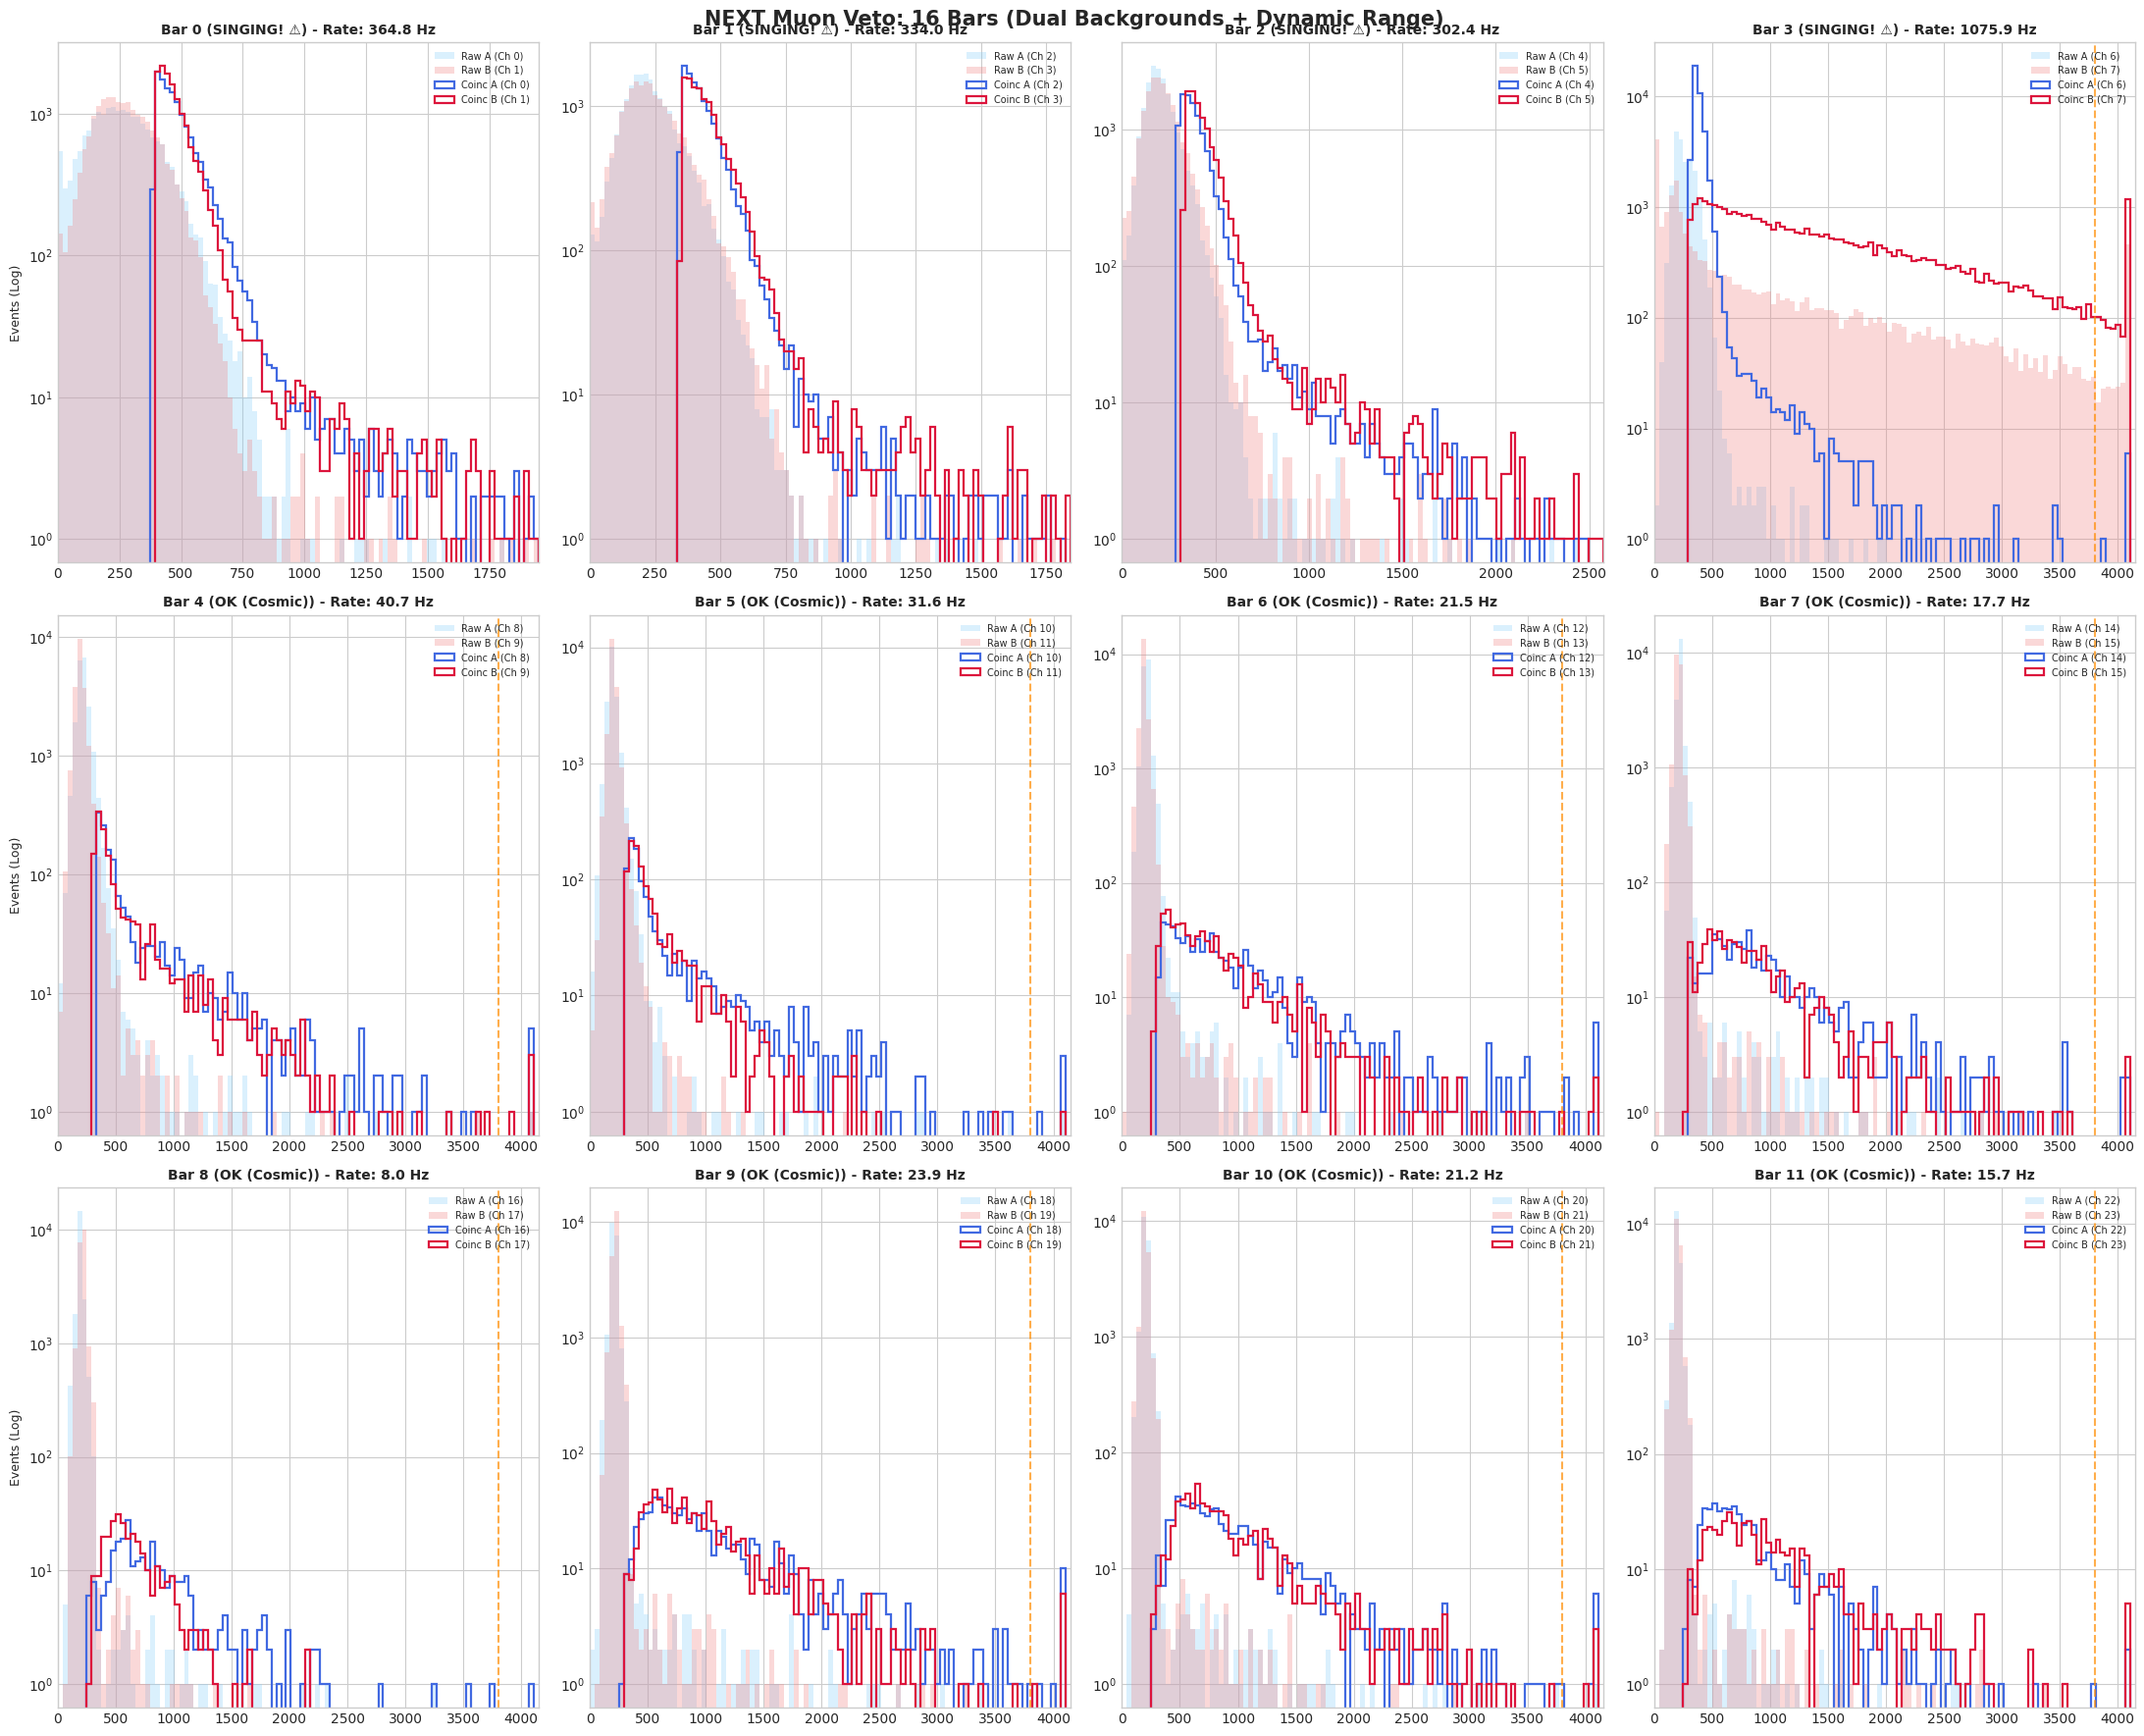

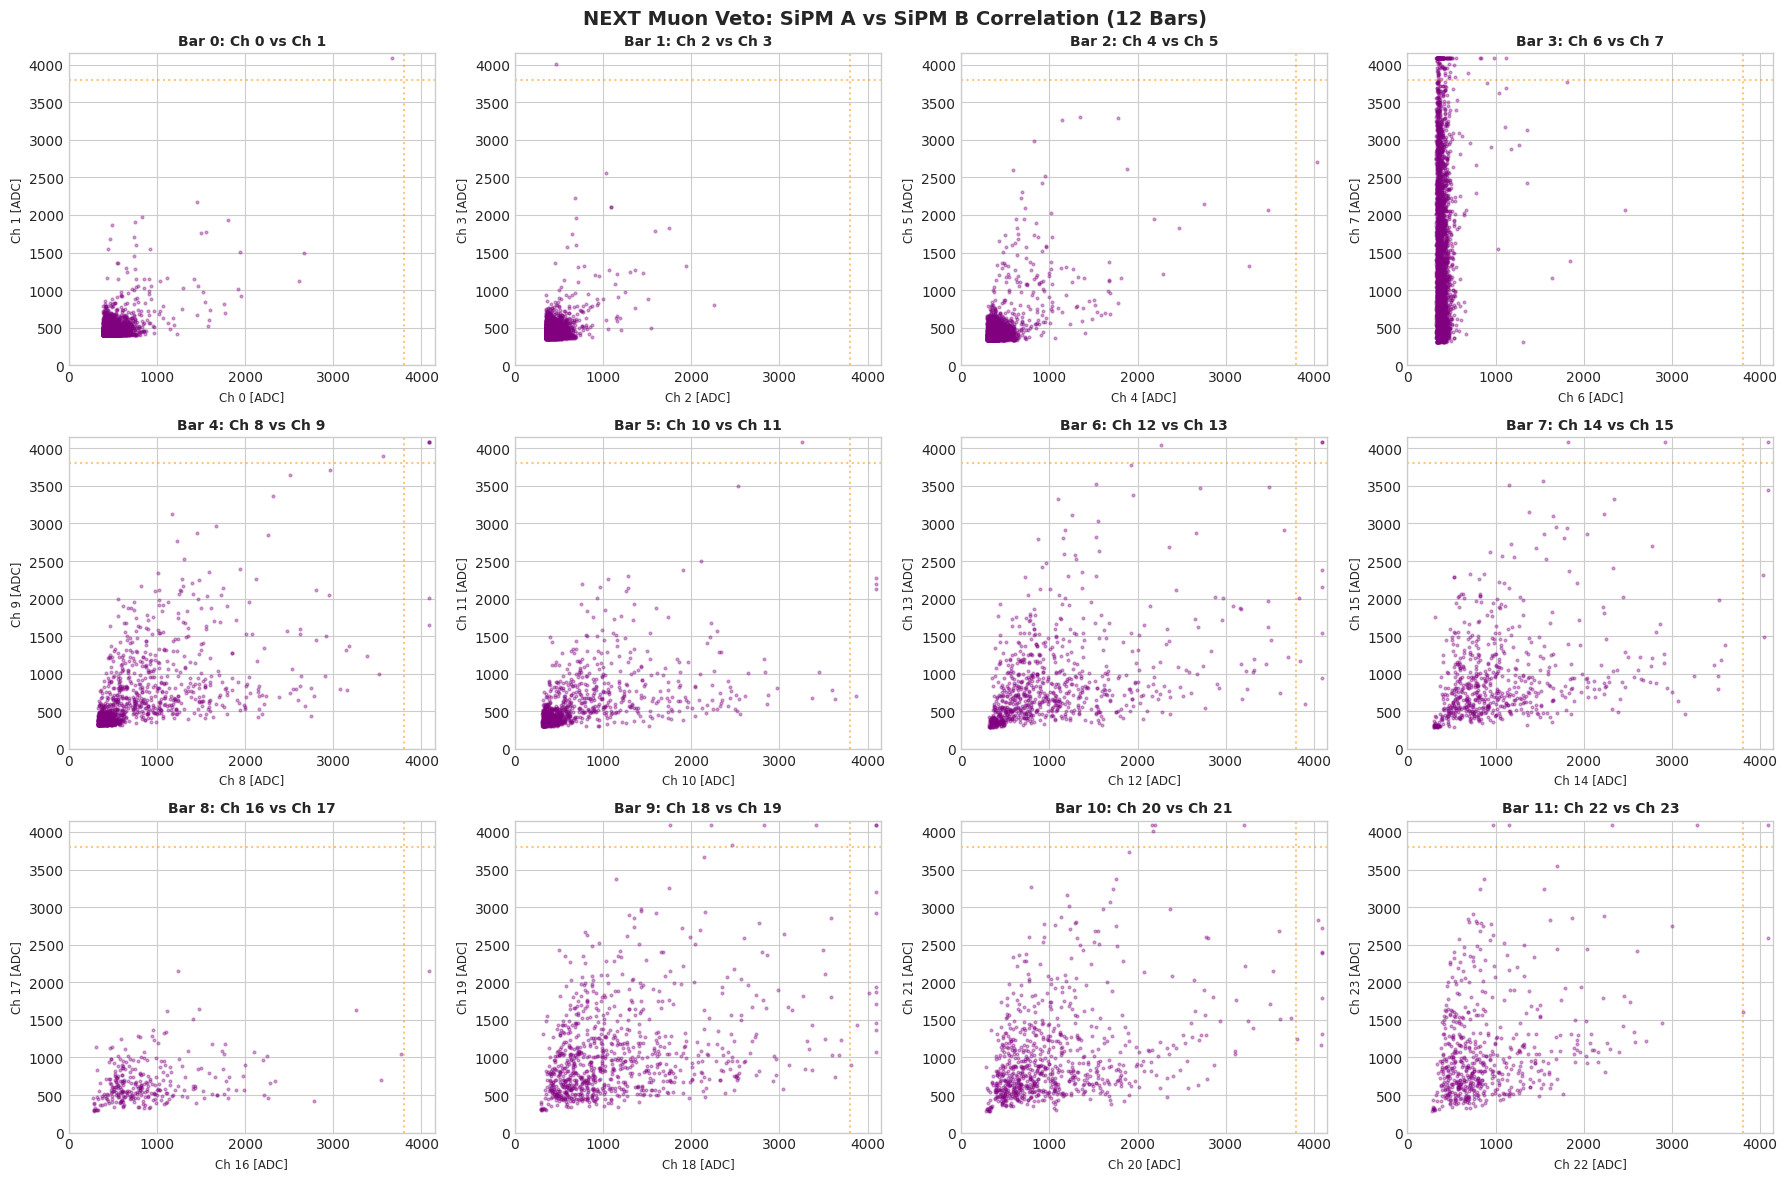

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_2.h5"

# All 16 bars mapped to the 32 CAEN channels
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION (All 32 Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")


# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        sub_indices = np.where(coinc_mask)[0]
        if len(sub_indices) > 3000:
            sub_indices = np.random.choice(sub_indices, 3000, replace=False)
        ax.scatter(q_a[sub_indices], q_b[sub_indices], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

# Hide any extra empty subplots
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: SiPM A vs SiPM B Correlation ({n_bars} Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_dynamic.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_dynamic.png")
print("\nDone! Now you can analyze any number of bars automatically.")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_3.h5 ...
Loaded 52,060 events over 36.35 seconds.
Total DAQ Trigger Rate: 1432.1 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 235.0 (±25.0)    | 242.0 (±25.0)    | 0.03    % | 0.06    % | 3,345       | 92.0       | SINGING! ⚠️ 
1     |  2, 3    | 215.0 (±25.0)    | 218.0 (±25.0)    | 0.10    % | 0.05    % | 2,001       | 55.0       | SINGING! ⚠️ 
2     |  4, 5    | 171.0 (±25.0)    | 174.0 (±25.0)    | 0.05    % | 0.00    % | 2,052       | 56.4       | SINGING! ⚠️ 
3     |  6, 7    | 204.0 (±25.0)    | 190.0 (±25.0)    | 0.00    % | 6.99    % | 9,341       | 257.0      | SINGING! ⚠️ 
4     |  8, 9    | 208.0 (±25.0)    | 191.0 (±25.0)    | 0.35    % | 0.12    % | 1,718       | 47.3       | OK (Cosmic) 
5     | 10, 11   | 192.0 (±25.0)    | 201.0 (±20.8)    | 0.41    % | 0.17    % | 1,206       | 33.2       | O

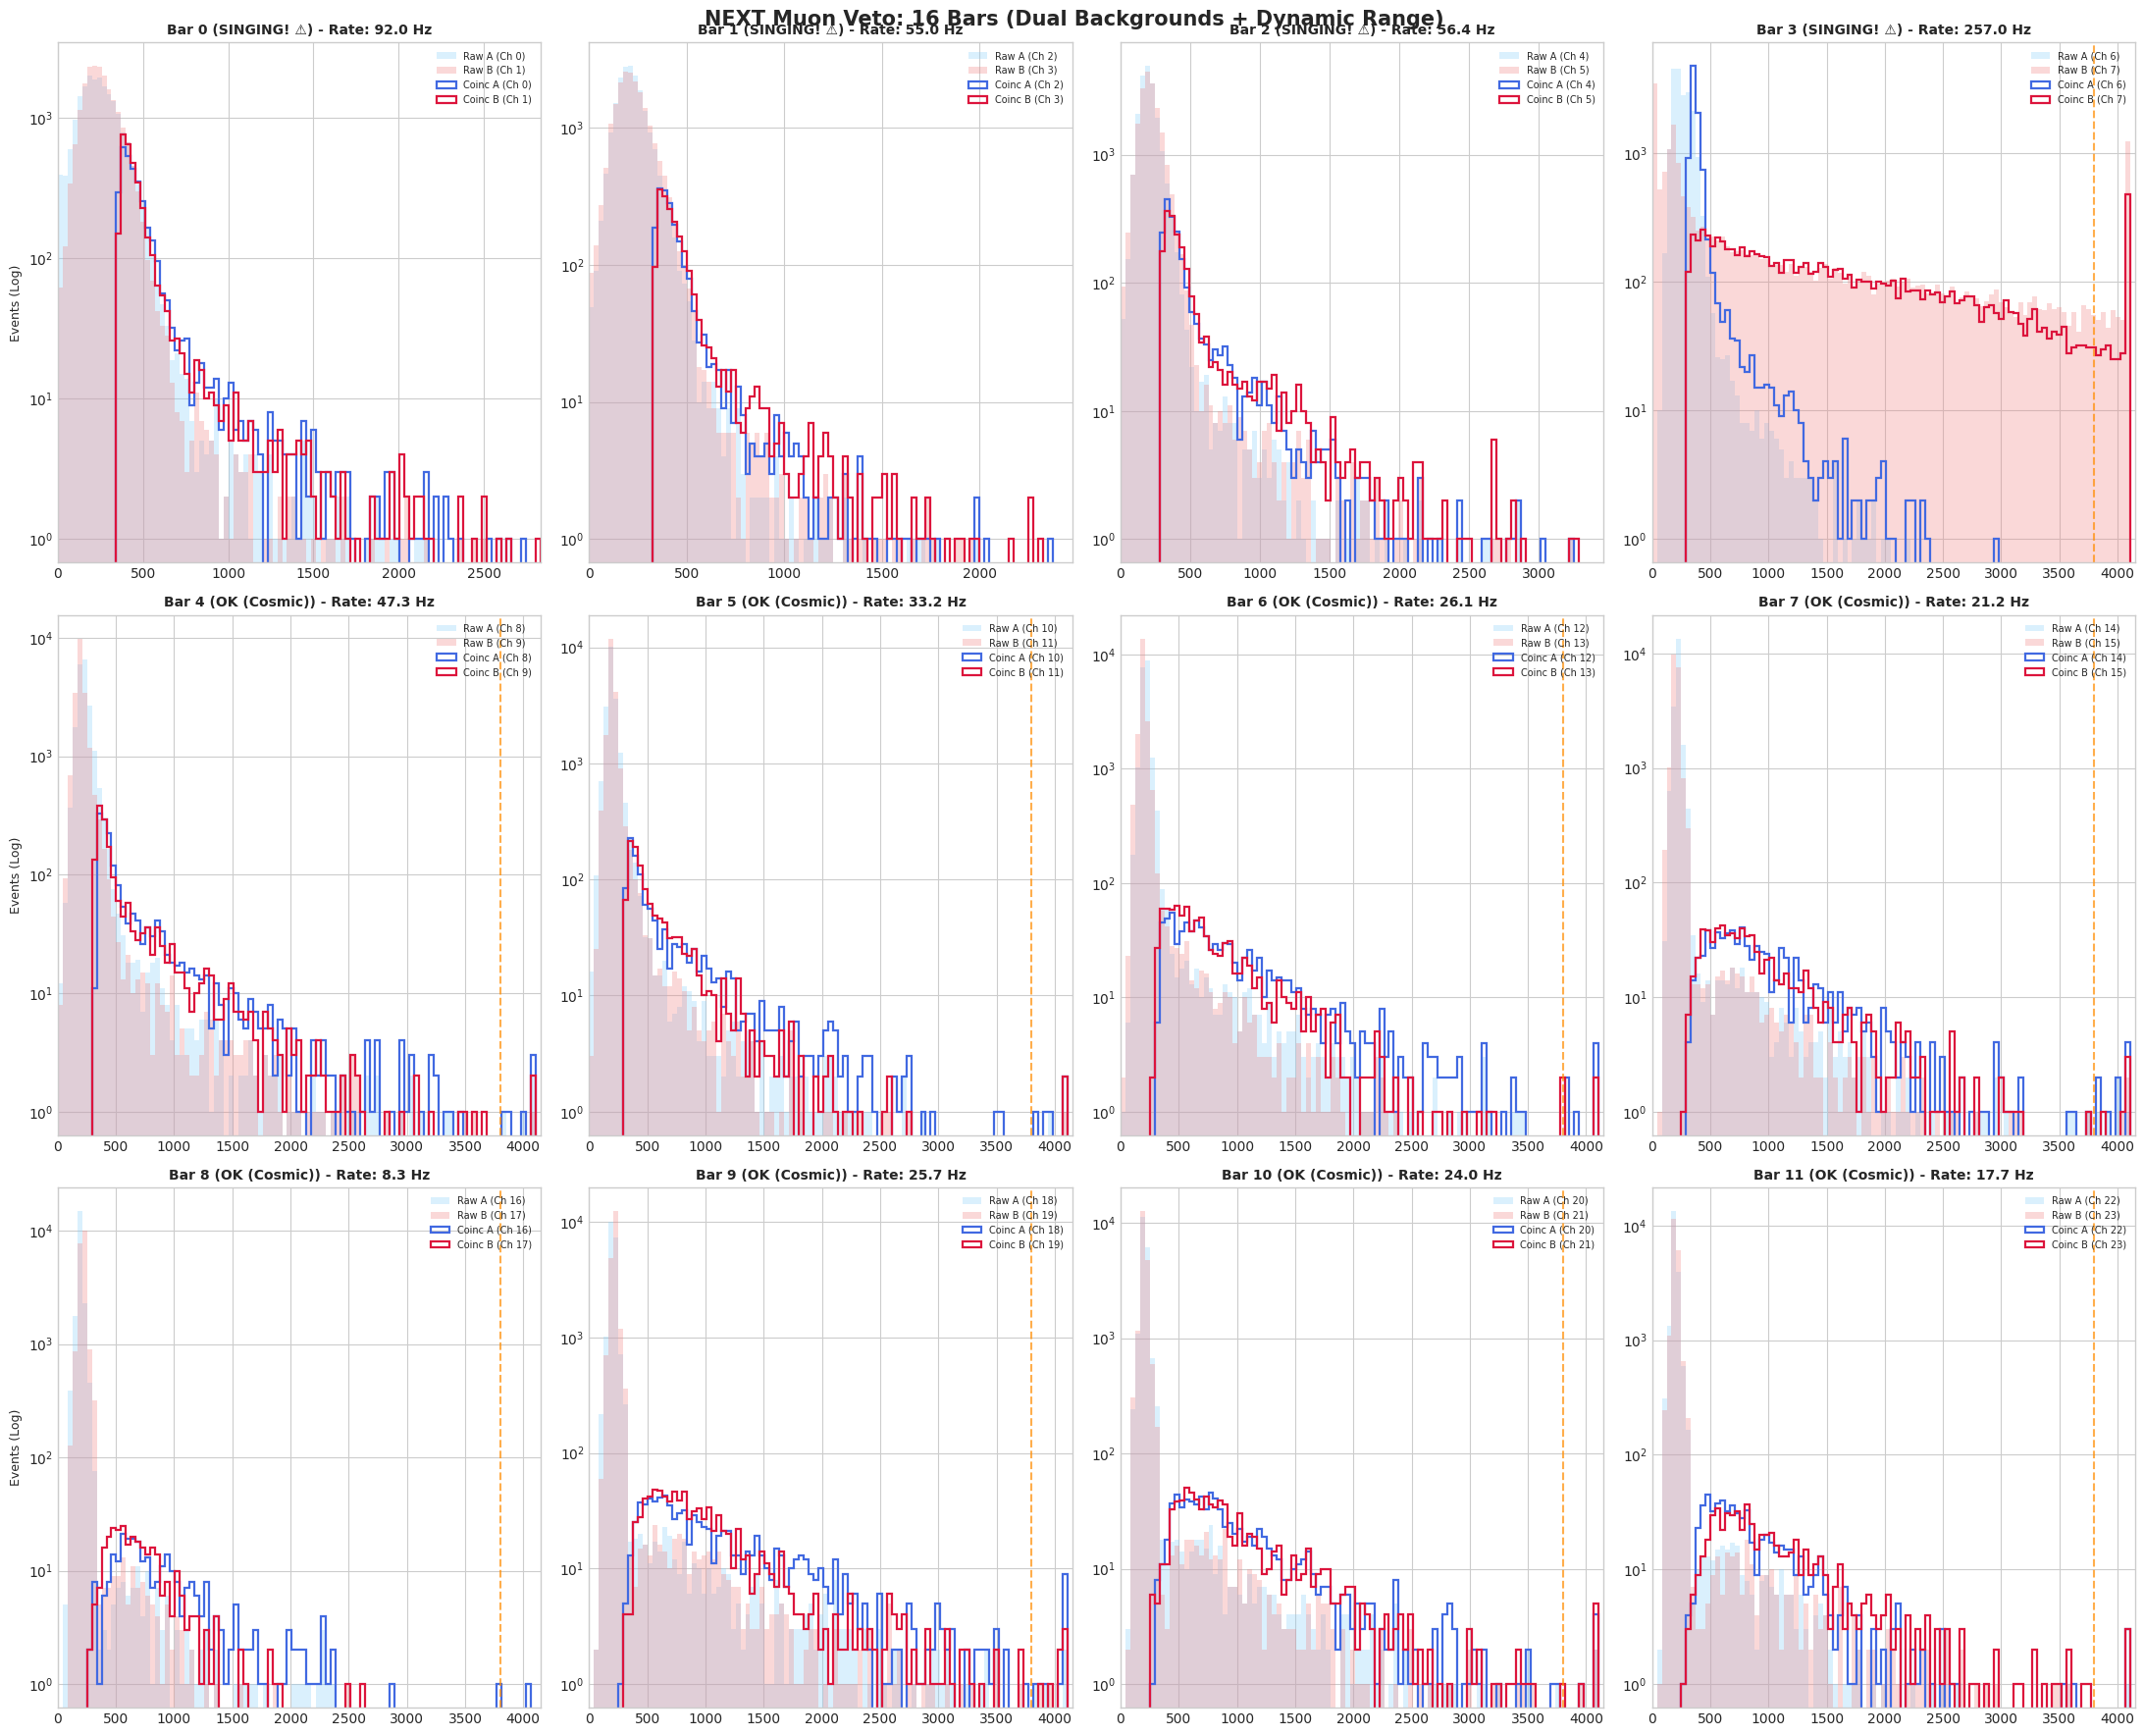

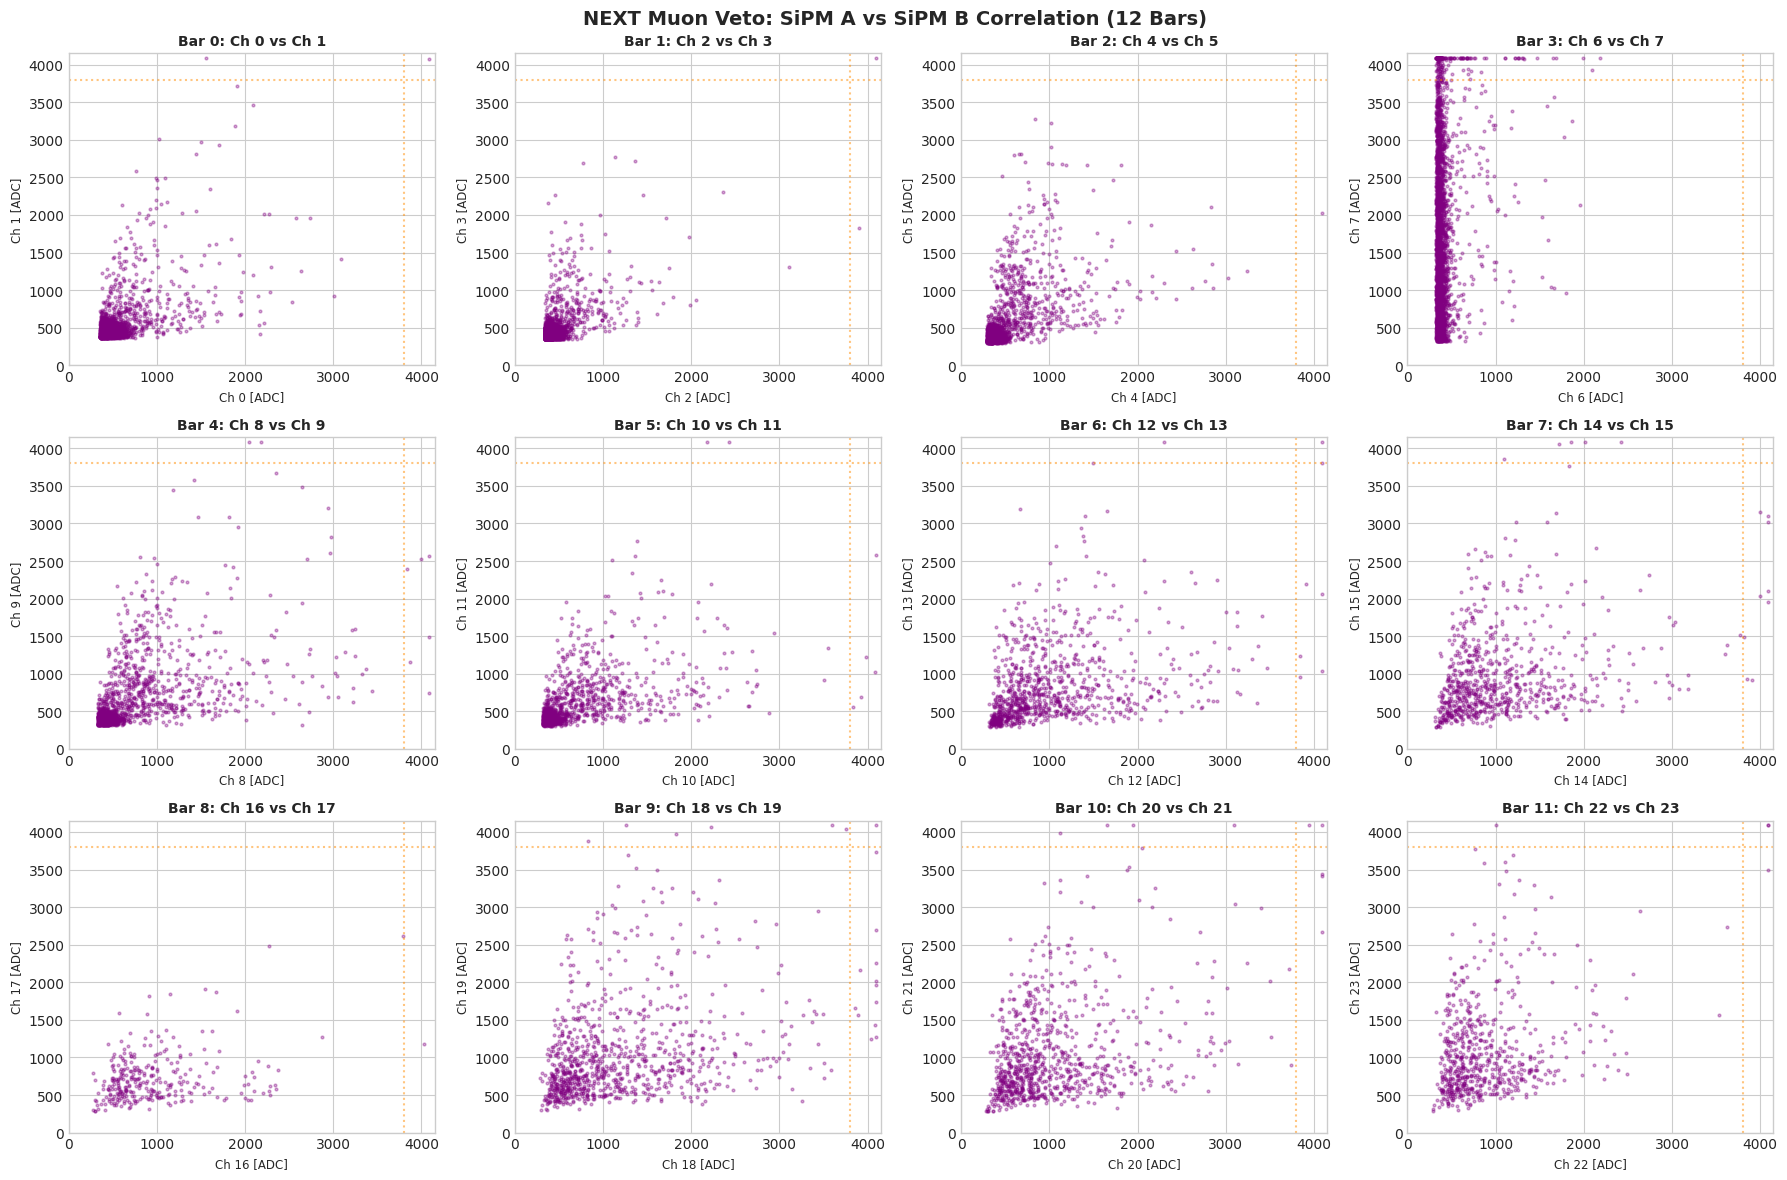

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_3.h5"

# All 16 bars mapped to the 32 CAEN channels
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION (All 32 Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")


# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        sub_indices = np.where(coinc_mask)[0]
        if len(sub_indices) > 3000:
            sub_indices = np.random.choice(sub_indices, 3000, replace=False)
        ax.scatter(q_a[sub_indices], q_b[sub_indices], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

# Hide any extra empty subplots
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: SiPM A vs SiPM B Correlation ({n_bars} Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_dynamic.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_dynamic.png")
print("\nDone! Now you can analyze any number of bars automatically.")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_4.h5 ...
Loaded 96,072 events over 89.85 seconds.
Total DAQ Trigger Rate: 1069.2 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 210.0 (±25.0)    | 220.0 (±25.0)    | 0.04    % | 0.07    % | 2,849       | 31.7       | OK (Cosmic) 
1     |  2, 3    | 212.0 (±25.0)    | 215.0 (±25.0)    | 0.09    % | 0.14    % | 2,112       | 23.5       | OK (Cosmic) 
2     |  4, 5    | 188.0 (±25.0)    | 205.0 (±25.0)    | 0.14    % | 0.19    % | 2,115       | 23.5       | OK (Cosmic) 
3     |  6, 7    | 285.0 (±25.0)    | 202.0 (±25.0)    | 0.04    % | 10.57   % | 4,871       | 54.2       | SINGING! ⚠️ 
4     |  8, 9    | 221.0 (±25.0)    | 192.0 (±25.0)    | 0.31    % | 0.09    % | 4,222       | 47.0       | OK (Cosmic) 
5     | 10, 11   | 191.0 (±25.0)    | 200.0 (±20.8)    | 0.57    % | 0.15    % | 3,341       | 37.2       | O

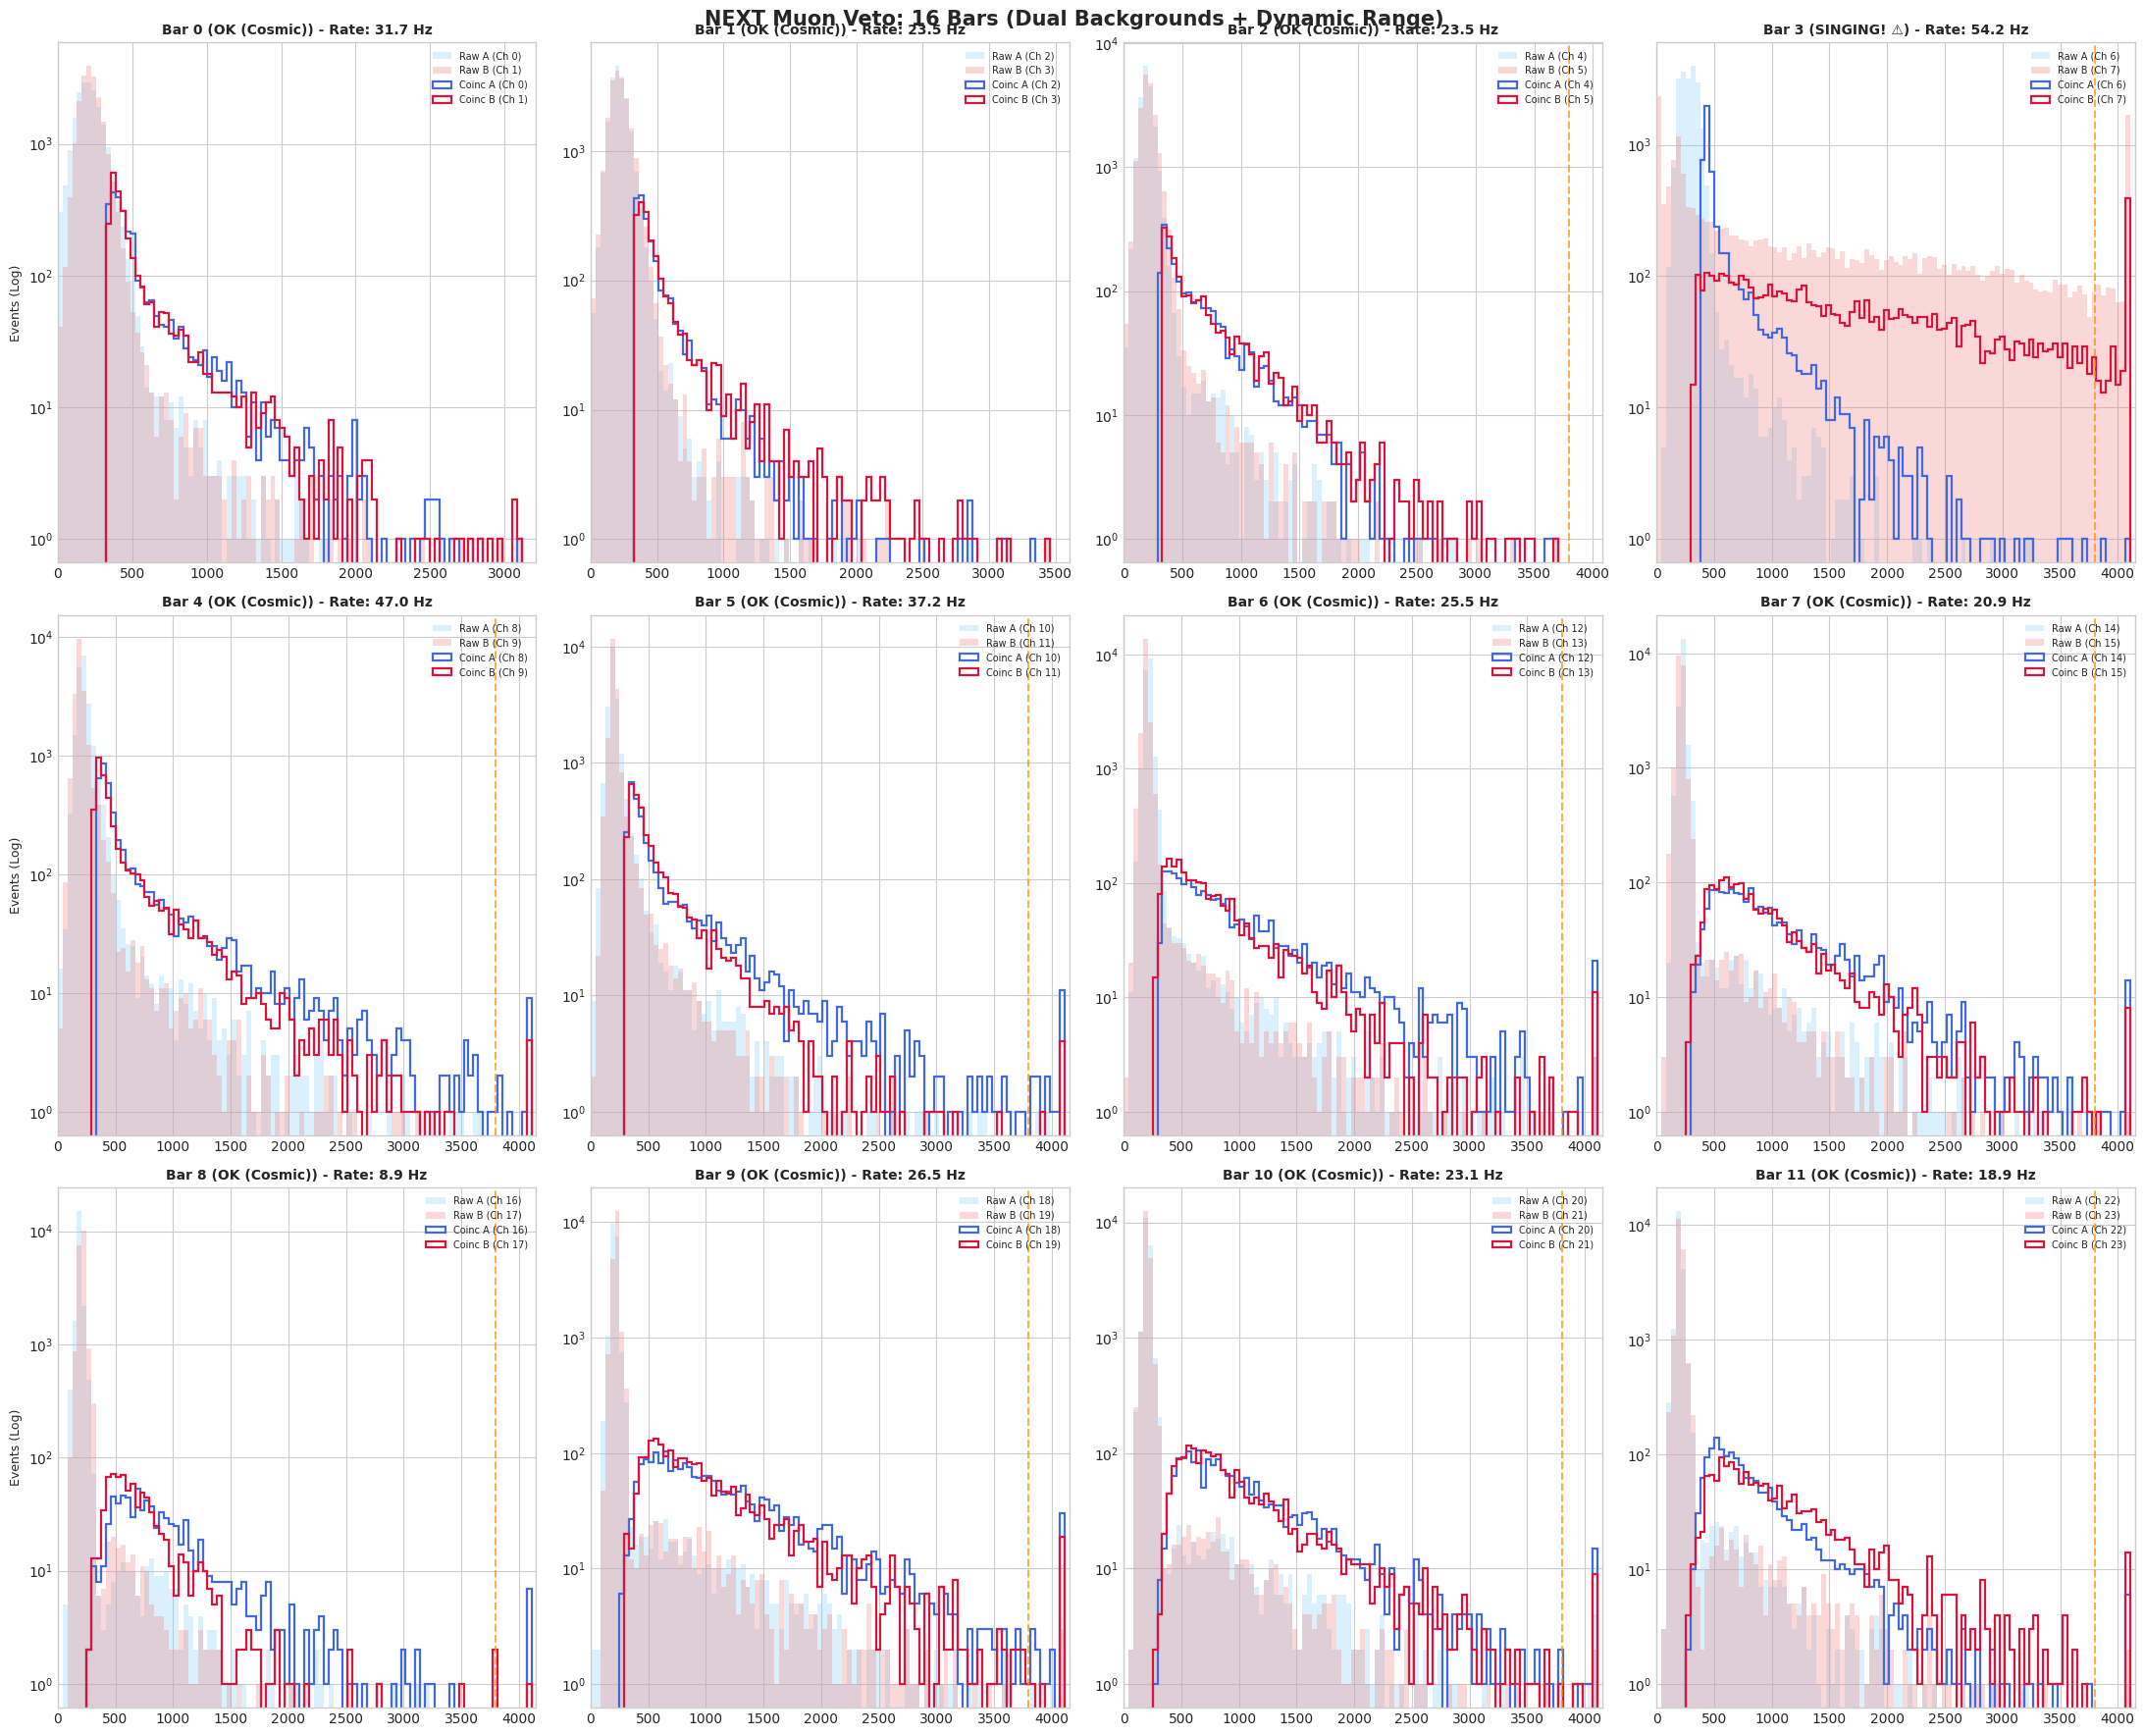

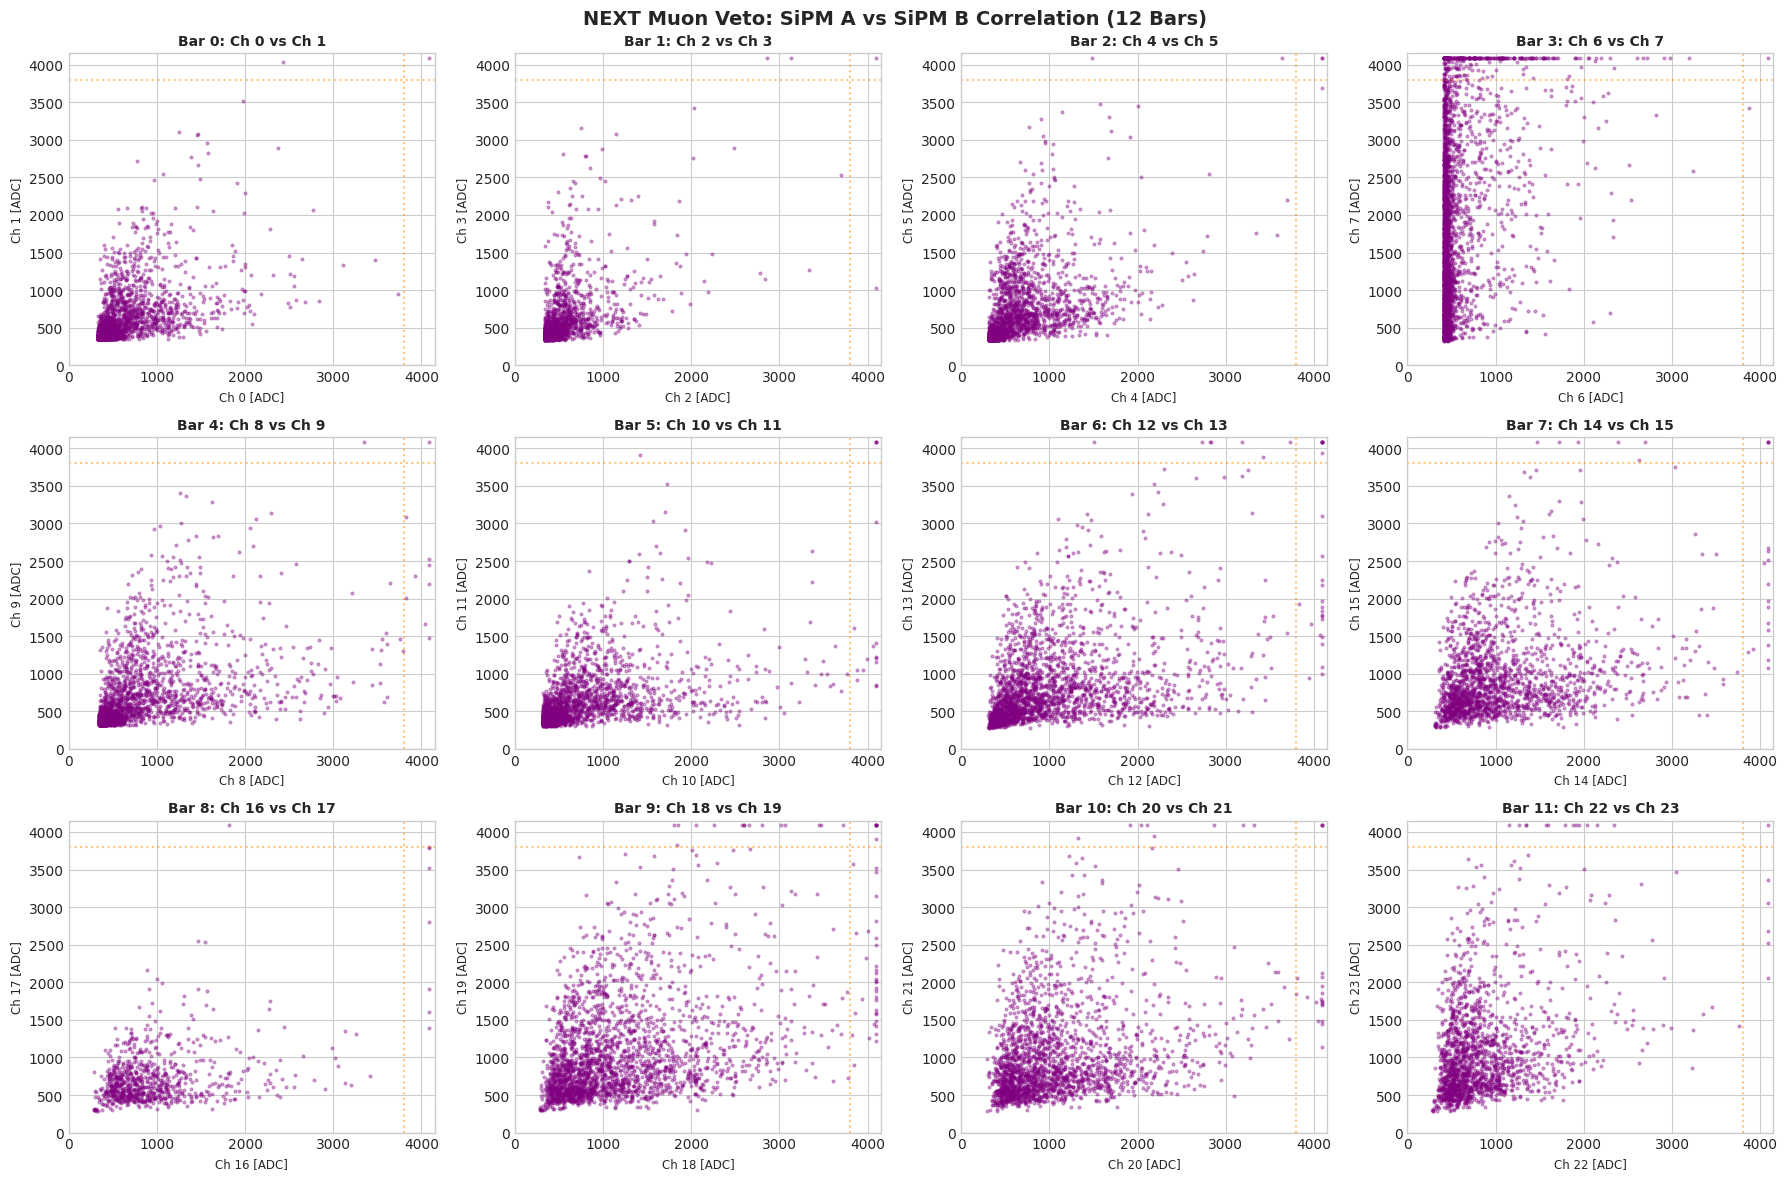

In [3]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_4.h5"

# All 16 bars mapped to the 32 CAEN channels
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION (All 32 Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")


# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        sub_indices = np.where(coinc_mask)[0]
        if len(sub_indices) > 3000:
            sub_indices = np.random.choice(sub_indices, 3000, replace=False)
        ax.scatter(q_a[sub_indices], q_b[sub_indices], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

# Hide any extra empty subplots
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: SiPM A vs SiPM B Correlation ({n_bars} Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_dynamic.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_dynamic.png")
print("\nDone! Now you can analyze any number of bars automatically.")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_4.h5 ...
Loaded 96,072 events over 89.85 seconds.
Total DAQ Trigger Rate: 1069.2 Hz

LEARNING ELECTRONIC NOISE FROM UNCONNECTED CHANNELS (24-31)
Channel    | Gain   | Pedestal (ADC)   | Noise RMS (ADC)  | Normalized Sigma/Gain
------------------------------------------------------------------------------
Ch 24      | 10     | 197.00           | 11.86            | 1.19                
Ch 25      | 9      | 185.00           | 11.86            | 1.32                
Ch 26      | 10     | 210.00           | 11.86            | 1.19                
Ch 27      | 10     | 204.00           | 11.86            | 1.19                
Ch 28      | 10     | 192.00           | 11.86            | 1.19                
Ch 29      | 10     | 211.00           | 11.86            | 1.19                
Ch 30      | 10     | 211.00           | 11.86            | 1.19                
Ch 31      | 10     | 199.00           | 11.86   

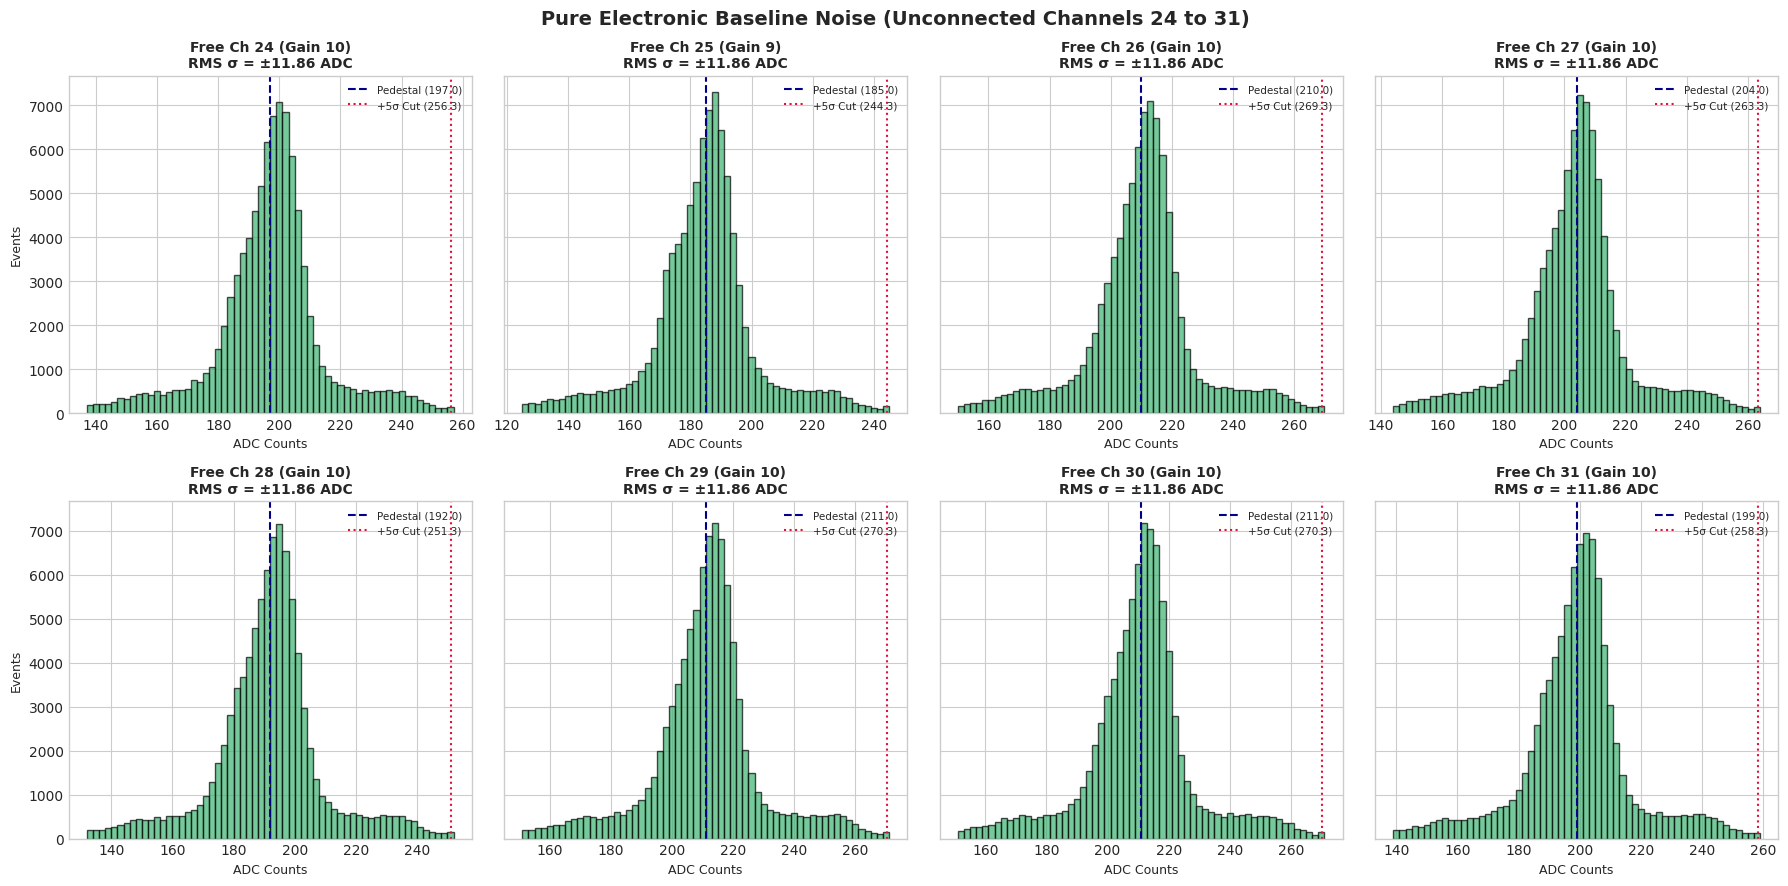

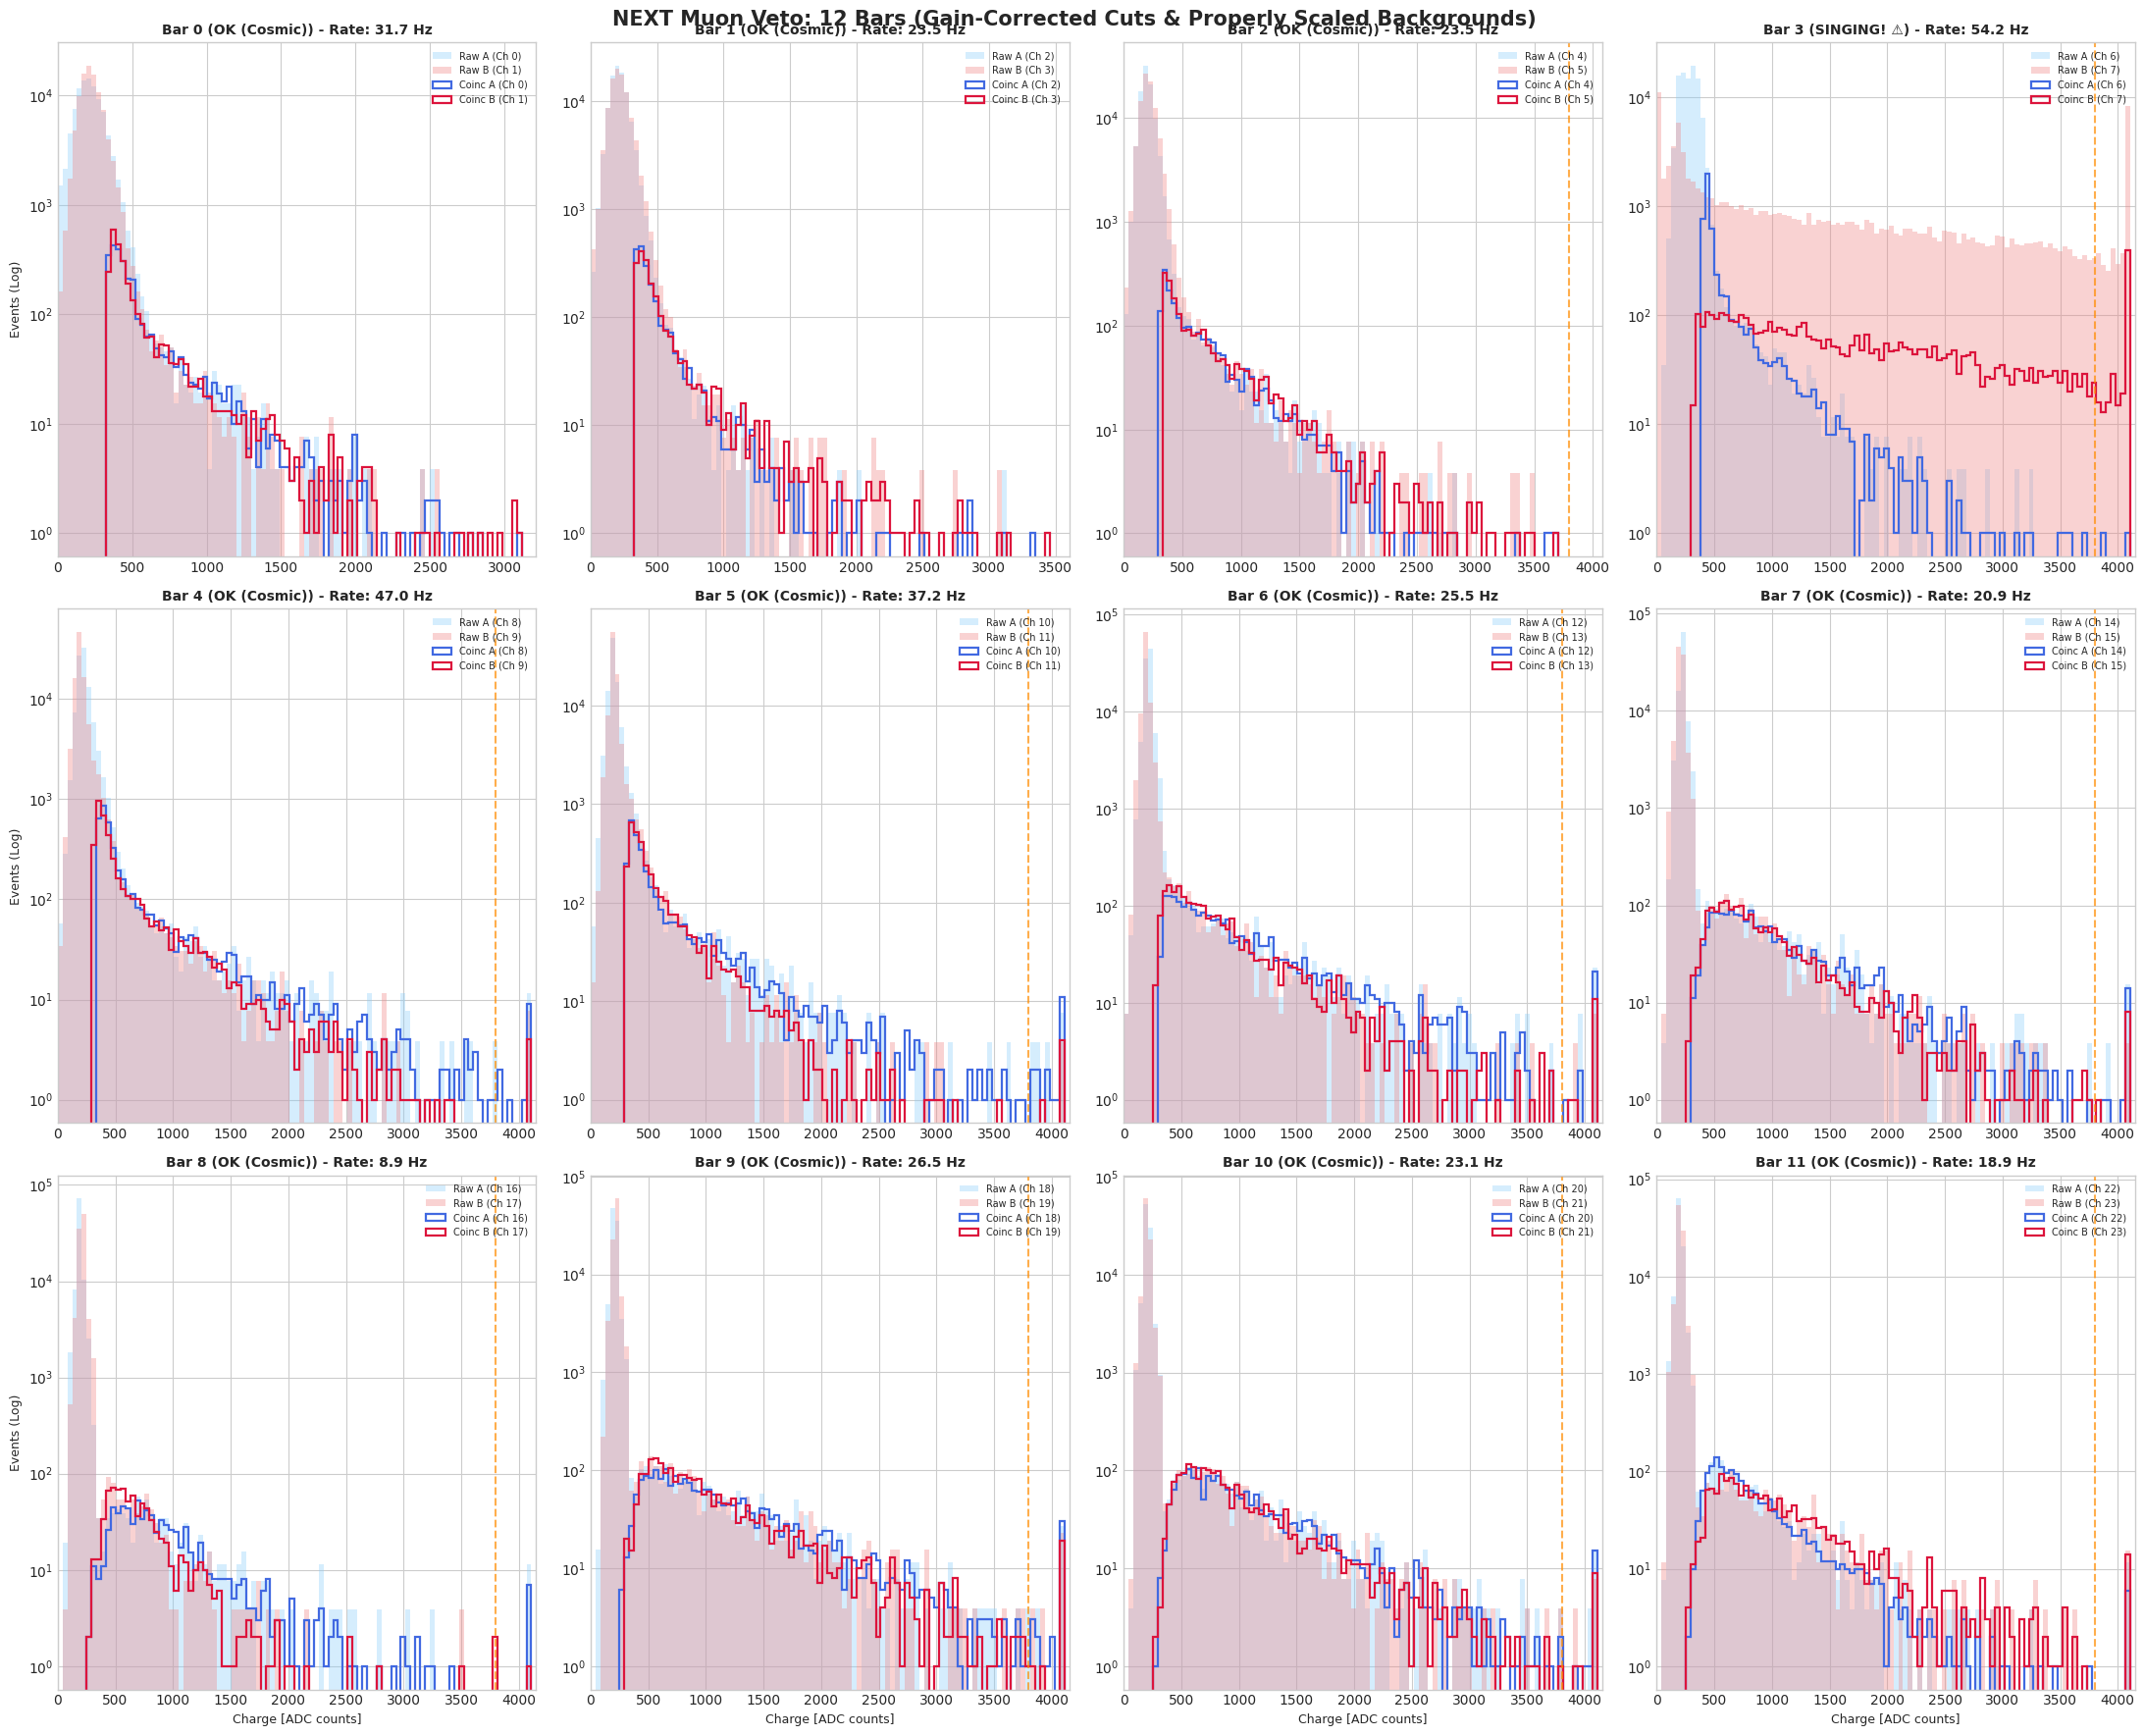

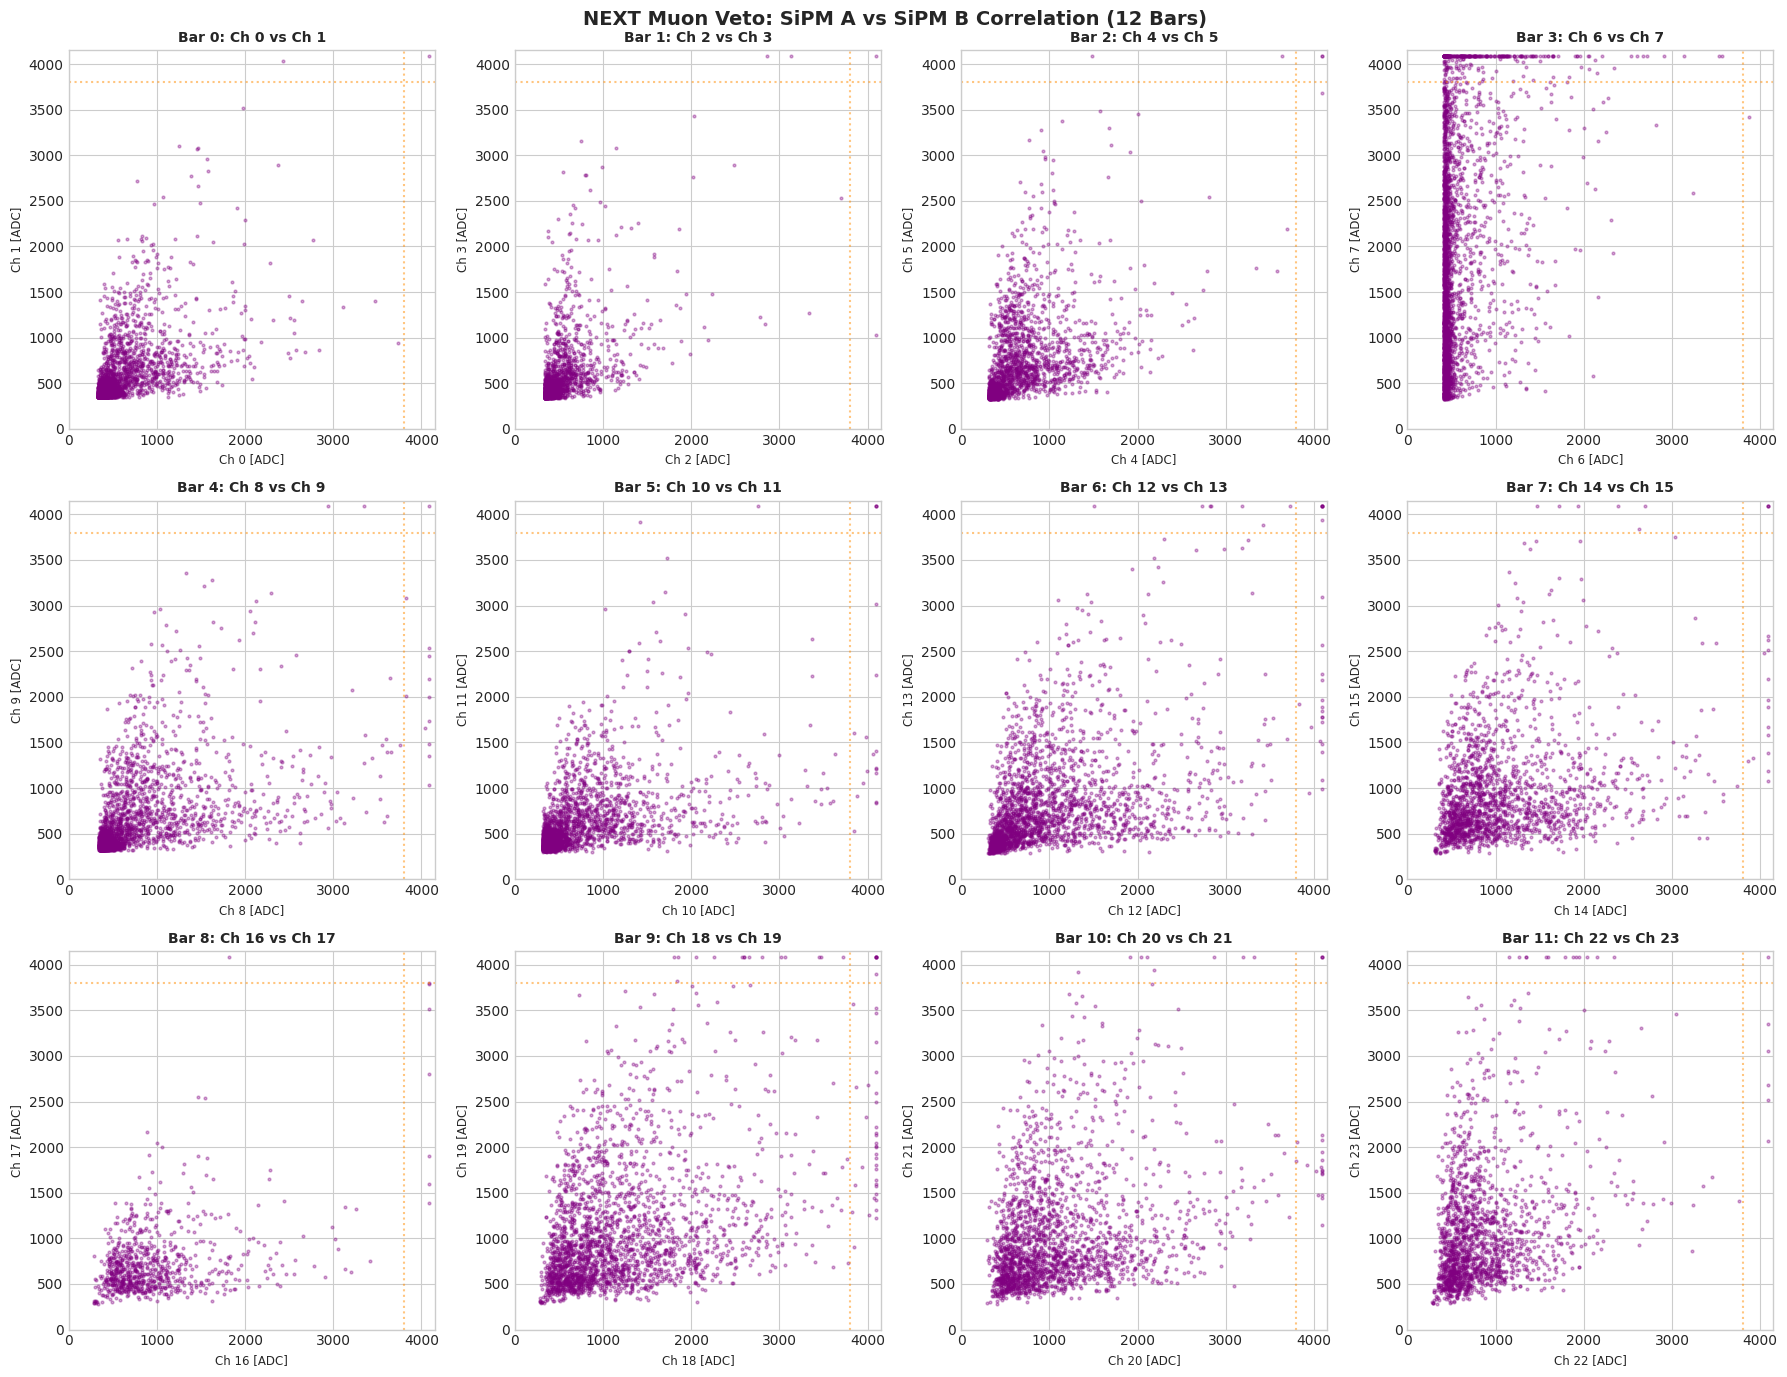

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION & HARDWARE MAPPING (From GUI Screenshot)
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M2_4.h5"

# Active 12 bars (Channels 0 to 23)
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
}

# Unconnected / Free channels used to characterize pure electronic noise
FREE_CHANNELS = [24, 25, 26, 27, 28, 29, 30, 31]

# Exact hardware configuration from your GUI
CHANNEL_CONFIG = {
    0:  {'gain': 8,  'bias': 104},
    1:  {'gain': 8,  'bias': 104},
    2:  {'gain': 8,  'bias': 110},
    3:  {'gain': 8,  'bias': 110},
    4:  {'gain': 8,  'bias': 112},
    5:  {'gain': 8,  'bias': 112},
    6:  {'gain': 5,  'bias': 102},
    7:  {'gain': 1,  'bias': 0},
    8:  {'gain': 10, 'bias': 140},
    9:  {'gain': 10, 'bias': 140},
    10: {'gain': 10, 'bias': 140},
    11: {'gain': 10, 'bias': 140},
    12: {'gain': 10, 'bias': 140},
    13: {'gain': 10, 'bias': 140},
    14: {'gain': 10, 'bias': 140},
    15: {'gain': 10, 'bias': 140},
    16: {'gain': 10, 'bias': 140},
    17: {'gain': 10, 'bias': 140},
    18: {'gain': 10, 'bias': 140},
    19: {'gain': 10, 'bias': 140},
    20: {'gain': 10, 'bias': 140},
    21: {'gain': 10, 'bias': 140},
    22: {'gain': 10, 'bias': 140},
    23: {'gain': 10, 'bias': 140},
    # Free channels:
    24: {'gain': 10, 'bias': 140},
    25: {'gain': 9,  'bias': 140},
    26: {'gain': 10, 'bias': 140},
    27: {'gain': 10, 'bias': 140},
    28: {'gain': 10, 'bias': 140},
    29: {'gain': 10, 'bias': 140},
    30: {'gain': 10, 'bias': 140},
    31: {'gain': 10, 'bias': 140},
}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
total_daq_rate = n_events / elapsed_time_s
print(f"Total DAQ Trigger Rate: {total_daq_rate:.1f} Hz\n")

# ==============================================================================
# 1. PURE ELECTRONIC NOISE LEARNING (Free Channels 24 to 31)
# ==============================================================================
print("=" * 78)
print("LEARNING ELECTRONIC NOISE FROM UNCONNECTED CHANNELS (24-31)")
print("=" * 78)
print(f"{'Channel':<10} | {'Gain':<6} | {'Pedestal (ADC)':<16} | {'Noise RMS (ADC)':<16} | {'Normalized Sigma/Gain':<20}")
print("-" * 78)

free_pedestals = {}
free_sigmas = {}
norm_sigmas = []

for ch in FREE_CHANNELS:
    ch_data = charges[:, ch]
    med = np.median(ch_data)
    mad = np.median(np.abs(ch_data - med))
    sigma = 1.4826 * mad
    if sigma < 1.0:
        sigma = np.std(ch_data)
    
    g = CHANNEL_CONFIG[ch]['gain']
    norm_s = sigma / g
    norm_sigmas.append(norm_s)
    
    free_pedestals[ch] = med
    free_sigmas[ch] = sigma
    print(f"Ch {ch:<7} | {g:<6} | {med:<16.2f} | {sigma:<16.2f} | {norm_s:<20.2f}")

# Characteristic electronic noise per unit gain
sigma_per_gain = float(np.median(norm_sigmas))
reference_sigma_g10 = sigma_per_gain * 10.0
print("-" * 78)
print(f"--> Average Pure Electronic Noise @ Gain 10: ±{reference_sigma_g10:.2f} ADC counts")
print(f"--> Normalized Electronic Sigma per Gain unit: {sigma_per_gain:.2f} ADC counts/Gain")
print("=" * 78 + "\n")

# ==============================================================================
# 2. BASELINE & GAIN-SCALED THRESHOLD DETERMINATION (Active Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    
    # Gain-scaled physical electronic threshold:
    ch_gain = CHANNEL_CONFIG[ch]['gain']
    ch_expected_elec_sigma = sigma_per_gain * ch_gain
    
    # Channel intrinsic spread (including residual dark counts)
    mad = np.median(np.abs(ch_data - mode_ped))
    ch_meas_sigma = 1.4826 * mad
    
    # Use the larger of measured or pure electronic noise (capped safely)
    eff_sigma = min(max(ch_meas_sigma, ch_expected_elec_sigma), 25.0)
    ped_rms[ch] = eff_sigma
    
    # Threshold = Pedestal + 5.0 * sigma, scaled with preamp gain
    min_cut = 35.0 * (ch_gain / 10.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * eff_sigma, min_cut)

# ==============================================================================
# 3. COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}
bar_masks = []

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    bar_masks.append(coincidence_mask)
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# 4. DAQ TRIGGER ATTRIBUTION & RATE RECONCILIATION
# ==============================================================================
coinc_matrix = np.column_stack(bar_masks)  # Shape: (N_events, 12)
bars_fired_per_event = np.sum(coinc_matrix, axis=1)

n_zero_bars = int(np.sum(bars_fired_per_event == 0))
n_single_bar = int(np.sum(bars_fired_per_event == 1))
n_multi_bars = int(np.sum(bars_fired_per_event >= 2))
sum_bar_hits = int(np.sum([bar_stats[b]['hits'] for b in BAR_MAP]))

print("=" * 65)
print("           DAQ TRIGGER ATTRIBUTION RECONCILIATION")
print("=" * 65)
print(f"Total DAQ Triggers Recorded:      {n_events:>10,d}  ({total_daq_rate:.1f} Hz)")
print(f"Sum of Hits across all Bars:      {sum_bar_hits:>10,d}  ({sum_bar_hits/elapsed_time_s:.1f} Hz)")
print("-" * 65)
print(f"  * Events with EXACTLY 1 Bar:    {n_single_bar:>10,d}  ({n_single_bar/n_events*100.1:.1f}%)")
print(f"  * Events with >= 2 Bars (Track):{n_multi_bars:>10,d}  ({n_multi_bars/n_events*100.1:.1f}%)")
print(f"  * Events with 0 Bars (Ghost):   {n_zero_bars:>10,d}  ({n_zero_bars/n_events*100.1:.1f}%)")
print("=" * 65)
if n_zero_bars > 0:
    print(f"[!] Notice: {n_zero_bars:,} triggers ({n_zero_bars/elapsed_time_s:.1f} Hz) were DAQ noise / ghost triggers")
    print("    where none of the 12 active bars satisfied the coincidence cut.")
print("\n")

# ==============================================================================
# PLOT 1: PURE ELECTRONIC NOISE OF UNCONNECTED CHANNELS (24-31)
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharey=True)
axes = axes.flatten()

for idx, ch in enumerate(FREE_CHANNELS):
    ax = axes[idx]
    ch_data = charges[:, ch]
    med = free_pedestals[ch]
    sig = free_sigmas[ch]
    g = CHANNEL_CONFIG[ch]['gain']
    
    ax.hist(ch_data, bins=60, range=(med - 60, med + 60), color='mediumseagreen', alpha=0.7, edgecolor='black')
    ax.axvline(med, color='darkblue', linestyle='--', label=f'Pedestal ({med:.1f})')
    ax.axvline(med + 5 * sig, color='crimson', linestyle=':', label=f'+5σ Cut ({med + 5*sig:.1f})')
    
    ax.set_title(f"Free Ch {ch} (Gain {g})\nRMS σ = ±{sig:.2f} ADC", fontsize=10, fontweight='bold')
    ax.set_xlabel("ADC Counts", fontsize=9)
    if idx % 4 == 0:
        ax.set_ylabel("Events", fontsize=9)
    ax.legend(fontsize=7.5, loc='upper right')

plt.suptitle("Pure Electronic Baseline Noise (Unconnected Channels 24 to 31)", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_pure_electronic_noise.png", dpi=200)
print("[+] Saved: veto_pure_electronic_noise.png")

# ==============================================================================
# PLOT 2: ACTIVE 12 BARS DUAL BACKGROUNDS (PROPERLY SCALED)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw backgrounds WITH WEIGHTS to match full dataset scale!
    sub_size = min(len(q_a), 25000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    weights = np.full(sub_size, len(q_a) / sub_size)
    
    ax.hist(q_a[sub_idx], bins=bins, weights=weights, color='lightskyblue', alpha=0.35, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, weights=weights, color='lightcoral', alpha=0.35, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 8:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 12 Bars (Gain-Corrected Cuts & Properly Scaled Backgrounds)", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_12bars_gain_corrected.png", dpi=200)
print("[+] Saved: veto_12bars_gain_corrected.png")

# ==============================================================================
# PLOT 3: 2D CORRELATION PLOTS (FULL RANGE 0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for b in range(12):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

plt.suptitle("NEXT Muon Veto: SiPM A vs SiPM B Correlation (12 Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_sipm_correlations_full.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! All diagnostic plots and rate reconciliations generated.")